# Presentation figures — PSCA CAR-T, radiation, and myeloid / cytotoxic programs

Five figures (plus one QC supplement) built from `code/mhcCytotoxExhaustion/` outputs, recomputing
every number that is plotted so each panel carries its own estimate, 95% CI and p-value.

| figure | claim it supports |
|---|---|
| **1** | PSCA CAR-T is associated with stronger NK-cell cytotoxic effector transcription, most clearly with RT; CD8 is under-sampled |
| **2** | PSCA CAR-T induces a reproducible interferon-response program across myeloid populations |
| **3** | PSCA CAR-T induces MHC-I and MHC-II antigen-processing machinery in myeloid cells (tumour MHC-II excluded: ambient RNA — supplement S3) |
| **4** | PSCA effects are far more consistently detected than RT effects at this time point; the exception is lower ISG / Cxcl9 in the abscopal tumour |
| **5** | SPP1-high macrophages carry a CCL2/7/12 program distinct from IFN-stimulated macrophages, yet still raise Cxcl9/10 under PSCA |

### Statistics used in every panel
* **Unit = tissue sample (one tumour of one mouse).** Program scores are pseudobulk (summed raw
  counts → log2 CPM → gene z-score across treated samples → mean over program genes), exactly as in
  `mhcCytotoxExhaustion/03`; effects are in **within-arm SD units**.
* **PSCA effect** = PSCA − TAG72, site-matched (mean over Tu1 and Tu2 of the within-site
  difference), per RT stratum; **pooled** = mean of the two strata; **CAR × RT** = RT stratum −
  non-RT stratum. **Direct / indirect RT** = RT − no-RT in Tu1 / Tu2, per CAR background.
* **p-values: exact relabelling** over every assignment of the label within each stratum (the
  `03` engine). **95% CIs: pooled-variance t intervals** on the same site-matched estimate
  (df = Σ(n_A + n_B − 2)); with 2-3 samples a side they are wide by construction, and that is the
  honest width.
* **Leave-one-mouse-out (LOO)**: each sample dropped in turn; a claim is LOO-stable if no single
  deletion flips the sign of either stratum.
* Gene-level heatmaps show **pydeseq2 log2FC** with **genome-wide BH padj** from `02`.

### Colour, by job (dataviz skill; palette validated, all-pairs)
* **CAR background (identity)** — PSCA `#eb6834` (slot 2), TAG72 `#2a78d6` (slot 1); untreated in
  muted grey `#898781` (context, not a series). Validator: CVD ΔE 24.7, normal-vision 33.6, PASS.
* **Tumour site** — marker shape: circle = Tu1 (irradiated in RT arms), square = Tu2 (abscopal).
* **Effect sizes (polarity)** — diverging blue ↔ red, grey midpoint; red = higher in the first
  group named (PSCA, RT, SPP1-high).
* **Expression magnitude** — one-hue violet ramp (kept off blue so it is never read as TAG72).

## 1. Config, style and data

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, itertools, logging, time
from pathlib import Path
import numpy as np, pandas as pd, h5py, anndata as ad
import scipy.sparse as sp
from scipy import stats
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib import font_manager
from statsmodels.stats.multitest import multipletests
logging.disable(logging.WARNING)

_HPC = Path("/coh_labs/yunroseli/Jona/CAR-T"); _LOC = Path("/Users/janzules/Roselab/Spatial/CAR_T")
PROJ = _LOC if _LOC.exists() else _HPC
SRC = PROJ/"results/mhc_cytotox"
SC_REF = (PROJ/"data/sc-reference/annotation_v4.h5ad" if PROJ is _LOC
          else PROJ/"data/zarr/fullDataset/annotating_references/annotation_v4.h5ad")
SIG_CSV = PROJ/"results/spp1_analysis/sc_spp1_tam_signature.csv"
OUT = PROJ/"results/mhc_cytotox_figures"; PANELS = OUT/"panels"
OUT.mkdir(parents=True, exist_ok=True); PANELS.mkdir(parents=True, exist_ok=True)
for f_ in ["pseudobulk_counts.parquet", "pseudobulk_meta.csv", "cell_panel.parquet", "programs.json",
           "de_all.parquet", "ledger_programs.csv", "ledger_chemokines.csv", "q1_ambient_estimate.csv",
           "q1_tumour_clean_vs_rest.csv"]:
    assert (SRC/f_).exists(), f"run code/mhcCytotoxExhaustion first — missing {f_}"
MIN_CELLS, MIN_CELLS_CELL, SEED = 10, 5, 0

# ---- style: dataviz reference palette & chrome -------------------------------------------------
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
C_PSCA, C_TAG72, C_NOTX = "#eb6834", "#2a78d6", "#898781"
CAR_COL = {"PSCA": C_PSCA, "TAG72": C_TAG72, "none": C_NOTX}
DIV = LinearSegmentedColormap.from_list("div", ["#104281", "#1c5cab", "#3987e5", "#86b6ef", "#cde2fb", "#f0efec",
                                                "#fad6d2", "#ea9a93", "#d75853", "#9e3432", "#762221"])
SEQ = LinearSegmentedColormap.from_list("seq", ["#d9dbfc", "#b6b7f3", "#918fe9", "#7067da", "#5342ba",
                                                "#382887", "#231859"])
SITE_MARK = {1: "o", 2: "s"}
mpl.rcParams.update({
    "font.family": ["Arial", "DejaVu Sans"],          # DejaVu is the glyph fallback (⁺ ★ ◆ ✓ ▼)
    "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False, "grid.color": GRID,
    "grid.linewidth": 0.6, "grid.linestyle": "-", "lines.solid_capstyle": "round",
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 300, "text.color": INK})

# ---- data --------------------------------------------------------------------------------------
PB = pd.read_parquet(SRC/"pseudobulk_counts.parquet")
PBM = pd.read_csv(SRC/"pseudobulk_meta.csv").set_index("key").loc[PB.index]
L = np.log2(PB.div(PB.sum(1), axis=0) * 1e6 + 1)
CAT = json.load(open(SRC/"programs.json")); PROGRAMS = CAT["programs"]
PROG = {k: v["genes"] for k, v in PROGRAMS.items()}
FAMILY = {k: v["family"] for k, v in PROGRAMS.items()}
PROG["cyto_core"] = ["Gzmb", "Prf1", "Nkg7", "Ctsw"]; FAMILY["cyto_core"] = "cytotoxicity"
DE = pd.read_parquet(SRC/"de_all.parquet")
LEDP = pd.read_csv(SRC/"ledger_programs.csv"); LEDC = pd.read_csv(SRC/"ledger_chemokines.csv")
cp = pd.read_parquet(SRC/"cell_panel.parquet")
design = pd.read_csv(SRC/"design_samples.csv").set_index("sample")
print(f"{len(PB)} pseudobulks | {len(cp):,} cells | {len(PROG)} programs")

NAME = {"Classical_Mono": "Classical mono", "IFN_stimulated_Mac": "IFN-stim mac", "M2_like_Mac": "M2-like mac",
        "Intermediate_Mac": "Intermediate mac", "SPP1_TAM": "SPP1-TAM", "cDC": "cDC", "Cancer_cell": "Tumour cells",
        "NK": "NK", "CD8_T": "CD8 T", "NKT": "NKT", "CD4_T": "CD4 T", "Treg": "Treg", "M1_like_Mac": "IFN-stim mac",
        "cytotoxic_lymph": "CD8+NK+NKT", "N1_like_Neu": "N1 neutrophil",
        "IFNG_Hallmark": "IFN-γ (Hallmark)", "IFNA_Hallmark": "IFN-α (Hallmark)", "IFNG_Reactome": "IFN-γ (Reactome)",
        "ISG_core": "ISG core", "MHC_I_machinery": "MHC-I machinery", "MHC_II_core": "MHC-II core",
        "cyto_effector_noCcl5": "Effector (no Ccl5)", "cyto_core": "Core: Gzmb Prf1 Nkg7 Ctsw",
        "CXCR3_ligands": "CXCL9/10"}

1158 pseudobulks | 93,548 cells | 66 programs


## 2. The statistics engine (inline — same definitions as `mhcCytotoxExhaustion/03`)

In [2]:
def group_scores(group, programs=PROG, min_cells=MIN_CELLS):
    """Sample x program z-scores from one group's pseudobulks (samples with >= min_cells cells)."""
    d = PBM[(PBM.group == group) & (PBM.n_cells >= min_cells)]
    Lg = L.loc[d.index]; expressed = Lg.columns[(Lg.mean() >= 1.0).values]
    tr = (d.arm != "NoTx").values
    Z = (Lg[expressed] - Lg.loc[tr, expressed].mean()) / Lg.loc[tr, expressed].std().replace(0, np.nan)
    Z = Z.dropna(axis=1); Z.index = d["sample"].values
    S = {}
    for k, gl in programs.items():
        g_ = [g for g in gl if g in Z.columns]
        if len(g_) >= (1 if FAMILY.get(k) == "chemokine" else 3): S[k] = Z[g_].mean(1)
    S = pd.DataFrame(S)
    meta = d.set_index("sample")[["arm", "site", "mouse", "n_cells"]]
    return S, meta


def sd_within(S, meta):
    t = S.join(meta)[meta.arm != "NoTx"]
    return t.groupby(["arm", "site"])[list(S.columns)].var().mean().pow(0.5)


def _cell(v, meta, A, B, site):
    idx = [i for i in meta.index[meta.arm.isin([A, B]) & (meta.site == site)] if np.isfinite(v.get(i, np.nan))]
    a = v[[i for i in idx if meta.loc[i, "arm"] == A]]; b = v[[i for i in idx if meta.loc[i, "arm"] == B]]
    if len(a) < 2 or len(b) < 2: return None
    x = np.r_[a.values, b.values]; k = len(a)
    null = [a.mean() - b.mean()]
    for c in itertools.combinations(range(len(x)), k):
        if c == tuple(range(k)): continue
        m = np.isin(np.arange(len(x)), c); null.append(x[m].mean() - x[~m].mean())
    ss = ((a - a.mean()) ** 2).sum() + ((b - b.mean()) ** 2).sum()
    return dict(d=a.mean() - b.mean(), null=np.array(null), ss=ss, df=len(a) + len(b) - 2,
                inv=1 / len(a) + 1 / len(b), nA=len(a), nB=len(b), samples=list(a.index) + list(b.index))


def _combine(nulls, how="mean", cap=60000, seed=SEED):
    g_ = np.random.default_rng(seed)
    out = nulls[0]
    for k, nb in enumerate(nulls[1:], start=2):
        out = ((out[:, None] * (k - 1) + nb[None, :]) / k).ravel() if how == "mean" else (out[:, None] - nb[None, :]).ravel()
        if len(out) > cap: out = np.r_[out[:1], g_.choice(out[1:], cap, replace=False)]
    return out


def _p(null): return float((np.abs(null) >= abs(null[0]) - 1e-12).mean())


def stratum(v, meta, cells):
    cs = [c for c in (_cell(v, meta, *cell) for cell in cells) if c is not None]
    if not cs: return None
    K = len(cs); df = sum(c["df"] for c in cs); s2 = sum(c["ss"] for c in cs) / max(df, 1)
    return dict(d=np.mean([c["d"] for c in cs]), se=np.sqrt(s2 * sum(c["inv"] for c in cs)) / K, df=df,
                null=_combine([c["null"] for c in cs]), samples=sorted({s for c in cs for s in c["samples"]}),
                n=" + ".join(f"{c['nA']}v{c['nB']}" for c in cs), cells=cells)


EFFECTS = {   # name: [(stratum label, [(A arm, B arm, site), ...]) x 2], interaction = second - first for PSCA
    "PSCA": [("no RT", [("CyPSCA", "CyT72", 1), ("CyPSCA", "CyT72", 2)]),
             ("RT", [("RTCyPSCA", "RTCyT72", 1), ("RTCyPSCA", "RTCyT72", 2)])],
    "direct RT": [("PSCA", [("RTCyPSCA", "CyPSCA", 1)]), ("TAG72", [("RTCyT72", "CyT72", 1)])],
    "indirect RT": [("PSCA", [("RTCyPSCA", "CyPSCA", 2)]), ("TAG72", [("RTCyT72", "CyT72", 2)])],
}


def effect(v, meta, eff, sdw=1.0):
    """Both strata, pooled main and CAR x RT, in units of sdw; 95% t-CIs; exact p; LOO flips."""
    T = 1.0 / sdw if np.isfinite(sdw) and sdw > 0 else np.nan
    out = {}
    st = [(lab, stratum(v, meta, cells)) for lab, cells in EFFECTS[eff]]
    for lab, s in st:
        if s is None: continue
        h = stats.t.ppf(0.975, s["df"]) * s["se"]
        out[lab] = dict(est=s["d"] * T, lo=(s["d"] - h) * T, hi=(s["d"] + h) * T, p=_p(s["null"]), n=s["n"], df=s["df"])
    if all(s is not None for _, s in st):
        (l1, s1), (l2, s2) = st
        se_m = np.sqrt(s1["se"] ** 2 + s2["se"] ** 2) / 2; df = s1["df"] + s2["df"]
        nm = _combine([s1["null"], s2["null"]], "mean"); h = stats.t.ppf(0.975, df) * se_m
        out["pooled"] = dict(est=(s1["d"] + s2["d"]) / 2 * T, lo=((s1["d"] + s2["d"]) / 2 - h) * T,
                             hi=((s1["d"] + s2["d"]) / 2 + h) * T, p=_p(nm), df=df)
        hi_, lo_ = (s2, s1) if eff == "PSCA" else (s1, s2)        # CAR x RT, always (RT eff in PSCA) - (in TAG72)
        ni = _combine([hi_["null"], lo_["null"]], "diff"); se_i = np.sqrt(s1["se"] ** 2 + s2["se"] ** 2)
        hh = stats.t.ppf(0.975, df) * se_i
        out["CARxRT"] = dict(est=(hi_["d"] - lo_["d"]) * T, lo=(hi_["d"] - lo_["d"] - hh) * T,
                             hi=(hi_["d"] - lo_["d"] + hh) * T, p=_p(ni))
        out["sign_agree"] = bool(np.sign(s1["d"]) == np.sign(s2["d"]))
        out["replicated"] = bool(out["sign_agree"] and out[l1]["p"] < 0.05 and out[l2]["p"] < 0.05)
        # leave-one-mouse-out: does dropping any single sample flip either stratum?
        base = [np.sign(s1["d"]), np.sign(s2["d"])]; flips = 0
        samples = sorted(set(s1["samples"]) | set(s2["samples"]))
        for s in samples:
            vv = v.drop(index=s)
            new = [stratum(vv, meta, cells) for _, cells in EFFECTS[eff]]
            flips += any(nw is not None and np.sign(nw["d"]) != b for nw, b in zip(new, base))
        out["loo"] = (flips, len(samples))
    return out


def gene_lvl(group, gene, min_cells=MIN_CELLS):
    d = PBM[(PBM.group == group) & (PBM.n_cells >= min_cells)]
    return pd.Series(L.loc[d.index, gene].values, index=d["sample"].values), d.set_index("sample")[["arm", "site", "mouse", "n_cells"]]


# consistency check against the analysis folder's own table
S_nk, M_nk = group_scores("NK"); e = effect(S_nk["cyto_effector_noCcl5"], M_nk, "PSCA", sd_within(S_nk, M_nk)["cyto_effector_noCcl5"])
print(f"NK effector (no Ccl5), PSCA: no RT {e['no RT']['est']:+.3f} (p={e['no RT']['p']:.3f}) | RT {e['RT']['est']:+.3f} "
      f"(p={e['RT']['p']:.3f}) | pooled {e['pooled']['est']:+.3f} (p={e['pooled']['p']:.3f}) | CAR x RT p={e['CARxRT']['p']:.3f}")
print("  analysis folder (03): no RT +0.371 (p=0.700) | RT +1.832 (p=0.030) | pooled +1.101 (p=0.048) | CAR x RT p=0.203")

NK effector (no Ccl5), PSCA: no RT +0.371 (p=0.700) | RT +1.832 (p=0.030) | pooled +1.101 (p=0.048) | CAR x RT p=0.203
  analysis folder (03): no RT +0.371 (p=0.700) | RT +1.832 (p=0.030) | pooled +1.101 (p=0.048) | CAR x RT p=0.203


## 3. Plotting helpers

In [3]:
COND = [("NoTx", 1), ("NoTx", 2), ("CyT72", 1), ("CyT72", 2), ("CyPSCA", 1), ("CyPSCA", 2),
        ("RTCyT72", 1), ("RTCyT72", 2), ("RTCyPSCA", 1), ("RTCyPSCA", 2)]
XPOS = {c: x for c, x in zip(COND, [0, 1, 2.6, 3.6, 4.6, 5.6, 7.2, 8.2, 9.2, 10.2])}
ARM_LAB = {"NoTx": "Untreated", "CyT72": "TAG72", "CyPSCA": "PSCA", "RTCyT72": "TAG72", "RTCyPSCA": "PSCA"}
CAR_OF = {"NoTx": "none", "CyT72": "TAG72", "CyPSCA": "PSCA", "RTCyT72": "TAG72", "RTCyPSCA": "PSCA"}


def panel_label(sf, letter, title, x=0.0, y=1.0):
    sf.text(x + 0.004, y - 0.006, letter, fontsize=14, fontweight="bold", va="top", ha="left", color=INK)
    tr = mpl.transforms.offset_copy(sf.transSubfigure, fig=sf.figure, x=11 * len(letter) + 8, y=-1.5, units="points")
    sf.text(x + 0.004, y - 0.006, title, fontsize=10.5, va="top", ha="left", color=INK, transform=tr)


def cond_axis(ax, conds=COND, groups=True, fs=7.5):
    xs = [XPOS[c] for c in conds]
    ax.set_xticks(xs); ax.set_xticklabels([f"Tu{s}" for _, s in conds], fontsize=fs)
    ax.set_xlim(min(xs) - 0.6, max(xs) + 0.6)
    arms = list(dict.fromkeys(a for a, _ in conds))
    for a in arms:
        under_label(ax, np.mean([XPOS[c] for c in conds if c[0] == a]), ARM_LAB[a], 1, fs)
    if groups:
        for lab, members in [("no RT", ["CyT72", "CyPSCA"]), ("RT", ["RTCyT72", "RTCyPSCA"])]:
            m = [XPOS[c] for c in conds if c[0] in members]
            if m: under_label(ax, np.mean(m), lab, 2, fs, bold=True)


def dots(ax, x, y, arm, site, s=34, hollow=False, z=3, alpha=1.0):
    col = CAR_COL[CAR_OF[arm]]
    ax.scatter(np.atleast_1d(x), np.atleast_1d(y), s=s, marker=SITE_MARK[site], zorder=z, alpha=alpha,
               facecolor="white" if hollow else col, edgecolor=col if hollow else "white",
               linewidth=1.2 if hollow else 0.8)


def mean_tick(ax, x, y, w=0.32, color=INK):
    if np.isfinite(y): ax.plot([x - w, x + w], [y, y], color=color, lw=1.6, zorder=4, solid_capstyle="butt")


def legend_car_site(fig, loc="upper center", bbox=(0.5, -0.005), extra=()):
    h = [Line2D([], [], marker="o", ls="", mfc=C_PSCA, mec="white", ms=7, label="PSCA CAR"),
         Line2D([], [], marker="o", ls="", mfc=C_TAG72, mec="white", ms=7, label="TAG72 CAR (non-specific)"),
         Line2D([], [], marker="o", ls="", mfc=C_NOTX, mec="white", ms=7, label="Untreated"),
         Line2D([], [], marker="o", ls="", mfc="white", mec=INK2, ms=6, label="Tu1 (irradiated in RT arms)"),
         Line2D([], [], marker="s", ls="", mfc="white", mec=INK2, ms=6, label="Tu2 (abscopal)")] + list(extra)
    fig.legend(handles=h, loc=loc, bbox_to_anchor=bbox, frameon=False, ncol=len(h), fontsize=8,
               handletextpad=0.3, columnspacing=1.1)


def fmt_p(p):
    return "p<0.001" if p < 0.001 else f"p={p:.3f}" if p < 0.1 else f"p={p:.2f}"


def under_label(ax, x, text, level=1, fs=7.5, bold=False, color=None):
    """Label below the x tick labels at a fixed distance in points (independent of axes height)."""
    off = -(9 + fs * 1.15) if level == 1 else -(9 + fs * 2.5)
    ax.annotate(text, (x, 0), xycoords=("data", "axes fraction"), xytext=(0, off), textcoords="offset points",
                ha="center", va="top", fontsize=fs, color=color or (INK if bold else INK2),
                fontweight="bold" if bold else "normal", annotation_clip=False)


def text_color(rgba):
    r, g, b = [c / 12.92 if c <= 0.04045 else ((c + 0.055) / 1.055) ** 2.4 for c in rgba[:3]]
    return INK if 0.2126 * r + 0.7152 * g + 0.0722 * b > 0.32 else "white"


def stars(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""


def annotated_heatmap(ax, M, vmax, fmt="{:+.1f}", star_mat=None, fs=7):
    norm = TwoSlopeNorm(0, -vmax, vmax)
    ax.imshow(np.ma.masked_invalid(M.values.astype(float)), cmap=DIV, norm=norm, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]
            if not np.isfinite(v):
                ax.text(j, i, "n/a", ha="center", va="center", fontsize=fs - 1, color=MUTED); continue
            s = fmt.format(v) + (("\n" + star_mat.values[i, j]) if star_mat is not None and star_mat.values[i, j] else "")
            ax.text(j, i, s, ha="center", va="center", fontsize=fs, color=text_color(DIV(norm(v))), linespacing=0.9)
    ax.set_xticks(range(M.shape[1])); ax.set_yticks(range(M.shape[0]))
    for sp_ in ax.spines.values(): sp_.set_visible(False)
    ax.tick_params(length=0)
    return norm


def save(fig, name):
    fig.savefig(OUT/f"{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(OUT/f"{name}.pdf", bbox_inches="tight")


def save_panel(func, size, name, *args):
    f = plt.figure(figsize=size); func(f, *args)
    f.savefig(PANELS/f"{name}.png", dpi=300, bbox_inches="tight"); plt.close(f)

## Figure 1 — PSCA-associated cytotoxic effector programs in NK and CD8 cells

**Title:** *Antigen-specific PSCA CAR-T treatment enhances NK-cell cytotoxic effector programs*

* **A** which cells are cytotoxic: per-cell core-module expression (colour) and the fraction of
  cells with **both** Gzmb and Prf1 counted in the same cell (size); open marks = fewer than two
  samples with >= 5 cells (sparse); numbers = cells. **A′** the core module against the broader
  `cyto_effector_noCcl5` score, per sample.
* **B** how strongly: PSCA − TAG72 effects with 95% CI by RT stratum (pooled and CAR × RT beneath),
  and every sample's score — the RT / Tu2 comparison is shaded.
* **C** whether more cells carry the machinery: per-sample fractions, co-expression recomputed per cell.
* **D** how abundant: % of all cells, so abundance is never read as per-cell activity.

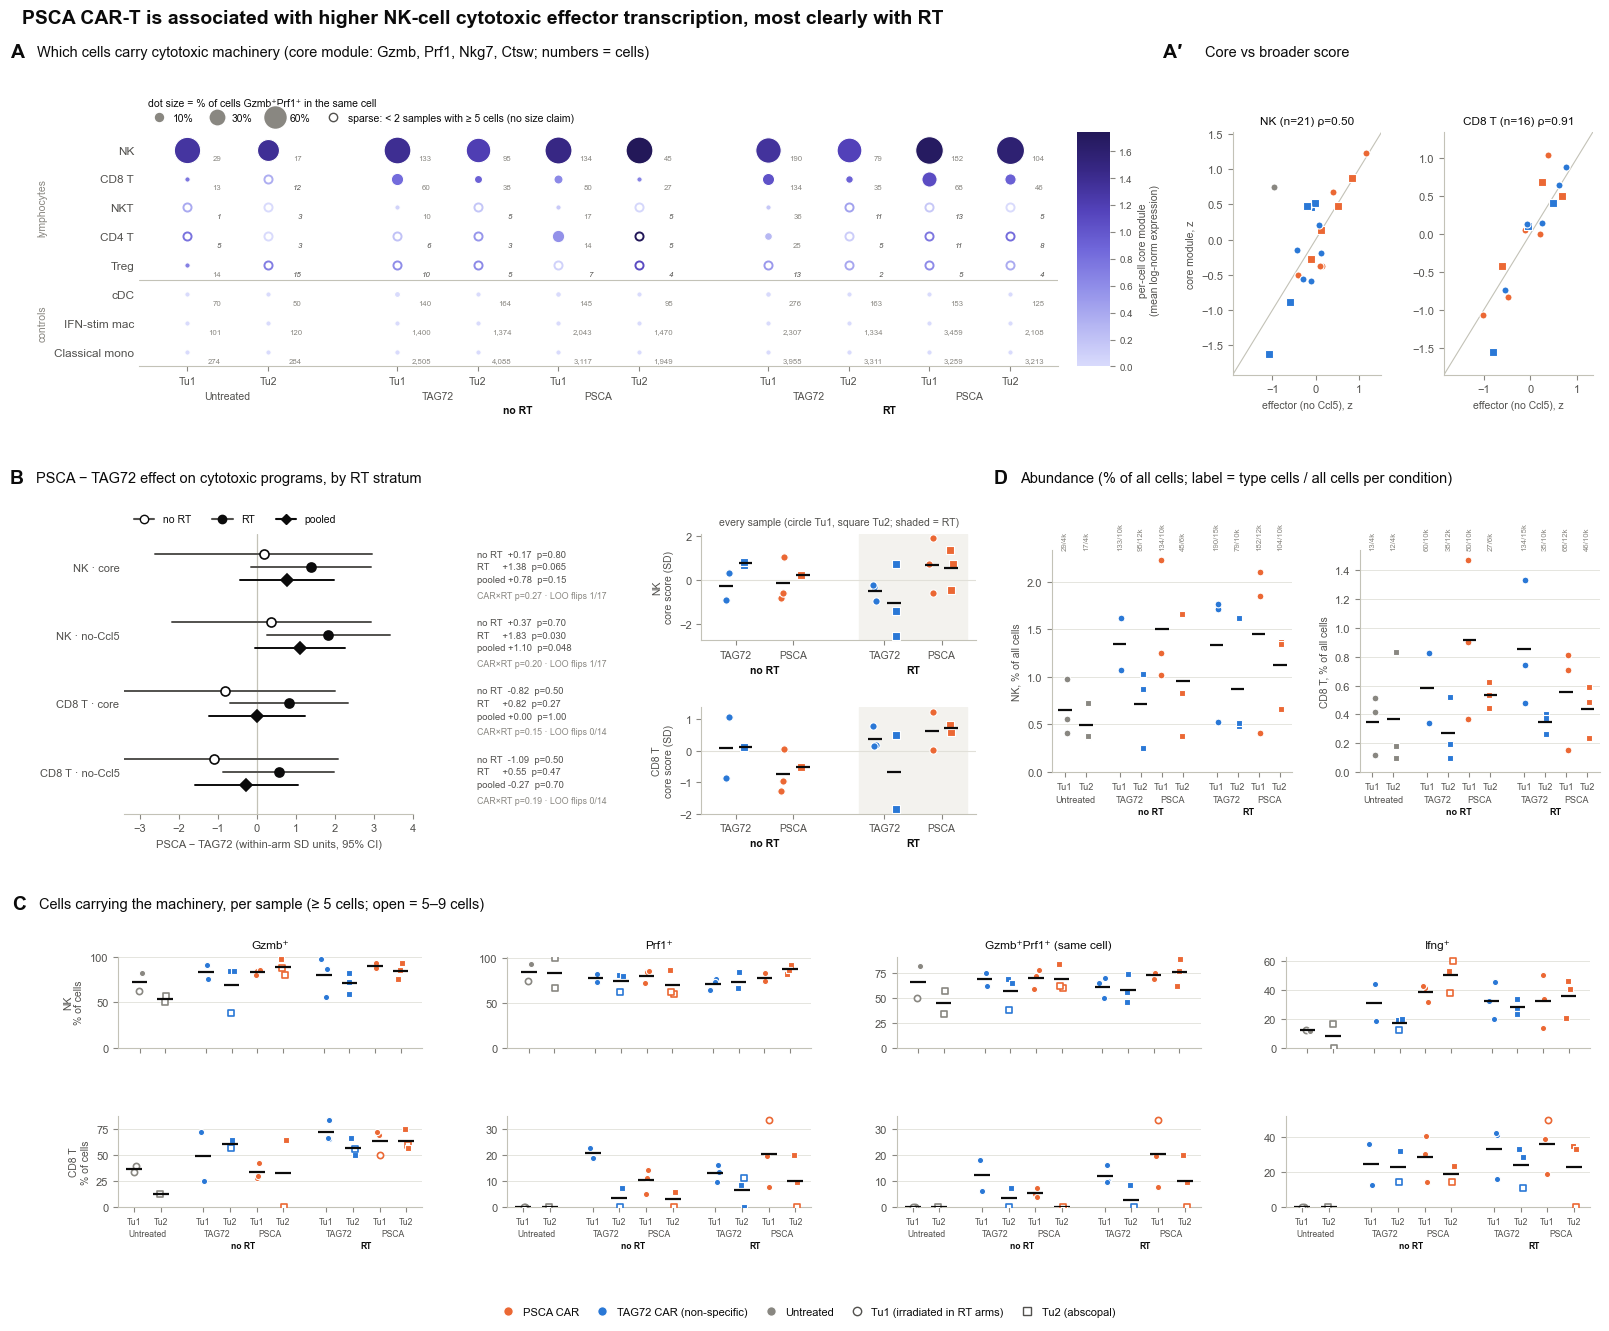

In [4]:
cp["cond"] = list(zip(cp.arm, cp.site))
CORE = PROG["cyto_core"]
ln = np.log1p(cp[CORE].div(cp.total_counts, axis=0) * 1e4)
cp["core"] = ln.mean(1)
cp["both"] = ((cp["Gzmb"] > 0) & (cp["Prf1"] > 0)).astype(float)
for g in ["Gzmb", "Prf1", "Ifng"]: cp[f"{g}+"] = (cp[g] > 0).astype(float)

ROWS1 = [("NK", cp.ct2 == "NK"), ("CD8_T", cp.ct2 == "CD8_T"), ("NKT", cp.ct2 == "NKT"),
         ("CD4_T", cp.ct2 == "CD4_T"), ("Treg", cp.ct2 == "Treg"), ("cDC", cp.ct2 == "cDC"),
         ("M1_like_Mac", cp.ct2 == "M1_like_Mac"), ("Classical_Mono", cp.ct2 == "Classical_Mono")]
per_s = []
for name, m in ROWS1:
    d = cp[m.values]
    g = d.groupby("sample").agg(n=("core", "size"), core=("core", "mean"), both=("both", "mean"),
                                gzmb=("Gzmb+", "mean"), prf1=("Prf1+", "mean"), ifng=("Ifng+", "mean"))
    per_s.append(g.join(design[["arm", "site"]]).assign(pop=name).reset_index())
PS1 = pd.concat(per_s, ignore_index=True)
PS1.to_csv(OUT/"fig1_per_sample_cytotoxic.csv", index=False)

DOT = []
for name, _ in ROWS1:
    for arm, site in COND:
        d = PS1[(PS1["pop"] == name) & (PS1.arm == arm) & (PS1.site == site)]
        u = d[d.n >= MIN_CELLS_CELL]
        DOT.append(dict(pop=name, arm=arm, site=site, cells=int(d.n.sum()), n_usable=len(u),
                        core=u.core.mean() if len(u) else (np.average(d.core, weights=d.n) if d.n.sum() else np.nan),
                        both=u.both.mean() if len(u) else (np.average(d.both, weights=d.n) if d.n.sum() else np.nan)))
DOT = pd.DataFrame(DOT)


def f1A(sf):
    gs = sf.add_gridspec(1, 2, width_ratios=[1, 0.035], left=0.115, right=0.955, top=0.78, bottom=0.22, wspace=0.04)
    ax = sf.add_subplot(gs[0]); cax = sf.add_subplot(gs[1])
    vmax = np.nanpercentile(DOT.core, 98); norm = Normalize(0, vmax)
    for i, (name, _) in enumerate(ROWS1):
        for c in COND:
            r = DOT[(DOT["pop"] == name) & (DOT.arm == c[0]) & (DOT.site == c[1])].iloc[0]
            if r.cells == 0 or not np.isfinite(r.core): continue
            col = SEQ(norm(r.core)); sparse = r.n_usable < 2
            size = 34 if sparse else 15 + 520 * np.clip(r.both, 0, 0.75)   # sparse cells carry no size claim
            ax.scatter(XPOS[c], i, s=size, facecolor="white" if sparse else col, edgecolor=col if sparse else "white",
                       linewidth=1.4 if sparse else 0.8, zorder=3)
            ax.text(XPOS[c] + 0.42, i + 0.30, f"{r.cells:,}", fontsize=5.6, color=MUTED if not sparse else INK2,
                    ha="right", va="center", style="italic" if sparse else "normal")
    ax.set_yticks(range(len(ROWS1))); ax.set_yticklabels([NAME[n] for n, _ in ROWS1], fontsize=8.5)
    ax.set_ylim(len(ROWS1) - 0.5, -0.6)
    ax.axhline(4.5, color=AXIS, lw=0.8)
    tr = mpl.transforms.blended_transform_factory(ax.transAxes, ax.transData)
    ax.text(-0.105, 2.0, "lymphocytes", transform=tr, rotation=90, ha="center", va="center", fontsize=7.5, color=MUTED)
    ax.text(-0.105, 6.0, "controls", transform=tr, rotation=90, ha="center", va="center", fontsize=7.5, color=MUTED)
    cond_axis(ax)
    ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
    cb = sf.colorbar(mpl.cm.ScalarMappable(norm, SEQ), cax=cax)
    cb.set_label("per-cell core module\n(mean log-norm expression)", fontsize=7.5); cb.outline.set_visible(False)
    cb.ax.tick_params(labelsize=7)
    h = [Line2D([], [], marker="o", ls="", mfc=MUTED, mec="white", ms=np.sqrt(15 + 520 * f) * 0.95,
                label=f"{int(100*f)}%") for f in (0.1, 0.3, 0.6)]
    h += [Line2D([], [], marker="o", ls="", mfc="white", mec=INK2, ms=6, label="sparse: < 2 samples with ≥ 5 cells (no size claim)")]
    ax.legend(handles=h, title="dot size = % of cells Gzmb⁺Prf1⁺ in the same cell", title_fontsize=7.5, fontsize=7.5,
              frameon=False, loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=4, columnspacing=1.2,
              handletextpad=0.4, alignment="left")
    panel_label(sf, "A", "Which cells carry cytotoxic machinery (core module: Gzmb, Prf1, Nkg7, Ctsw; numbers = cells)")


S_cd8, M_cd8 = group_scores("CD8_T")


def f1A2(sf):
    gs = sf.add_gridspec(1, 2, left=0.16, right=0.97, top=0.78, bottom=0.2, wspace=0.42)
    for k, (grp, S, M) in enumerate([("NK", S_nk, M_nk), ("CD8_T", S_cd8, M_cd8)]):
        ax = sf.add_subplot(gs[k])
        x, y = S["cyto_effector_noCcl5"], S["cyto_core"]
        for smp in S.index:
            dots(ax, x[smp], y[smp], M.loc[smp, "arm"], M.loc[smp, "site"], s=26)
        lim = [min(x.min(), y.min()) - 0.3, max(x.max(), y.max()) + 0.3]
        ax.plot(lim, lim, color=AXIS, lw=0.8, zorder=1); ax.set_xlim(lim); ax.set_ylim(lim)
        r = stats.spearmanr(x, y).statistic
        ax.set_title(f"{NAME[grp]} (n={len(S)}) ρ={r:.2f}", fontsize=8.5, color=INK)
        ax.set_xlabel("effector (no Ccl5), z", fontsize=7.5)
        if k == 0: ax.set_ylabel("core module, z", fontsize=7.5)
    panel_label(sf, "A′", "Core vs broader score")


def f1B(sf):
    gs = sf.add_gridspec(2, 3, width_ratios=[1.0, 0.48, 0.95], left=0.12, right=0.985, top=0.84, bottom=0.17,
                         wspace=0.32, hspace=0.62)
    axf = sf.add_subplot(gs[:, 0]); axt = sf.add_subplot(gs[:, 1], sharey=axf); axt.axis("off"); axt.set_xlim(0, 1)
    rows = [("NK", "cyto_core"), ("NK", "cyto_effector_noCcl5"), ("CD8_T", "cyto_core"), ("CD8_T", "cyto_effector_noCcl5")]
    ytick, ylab, yy = [], [], 0
    RES = {}
    for grp, prog in rows:
        S, M = (S_nk, M_nk) if grp == "NK" else (S_cd8, M_cd8)
        e = effect(S[prog], M, "PSCA", sd_within(S, M)[prog]); RES[(grp, prog)] = e
        for j, (lab, mk, filled) in enumerate([("no RT", "o", False), ("RT", "o", True), ("pooled", "D", True)]):
            if lab not in e: continue
            y = yy + j * 0.28
            axf.plot([e[lab]["lo"], e[lab]["hi"]], [y, y], color=INK if lab == "pooled" else INK2, lw=1.4)
            axf.plot(e[lab]["est"], y, marker=mk, ms=6.5 if lab != "pooled" else 6, mfc=(INK if filled else "white"),
                     mec=INK, mew=1.2, ls="")
            axt.text(-0.08, y, f"{lab:<6s} {e[lab]['est']:+.2f}  {fmt_p(e[lab]['p'])}", fontsize=6.8, va="center", color=INK2)
        ytick.append(yy + 0.28); ylab.append(f"{NAME[grp]} · {'core' if prog == 'cyto_core' else 'no-Ccl5'}")
        ci = e.get("CARxRT"); lf = e.get("loo", (np.nan, np.nan))
        axt.text(-0.08, yy + 0.90, f"CAR×RT {fmt_p(ci['p'])} · LOO flips {lf[0]}/{lf[1]}", fontsize=6.4, color=MUTED, va="center")
        yy += 1.50
    axf.axvline(0, color=AXIS, lw=0.9, zorder=0)
    axf.set_yticks(ytick); axf.set_yticklabels(ylab, fontsize=8); axf.set_ylim(yy - 0.3, -0.45)
    axf.set_xlim(-3.4, 4.0); axf.set_xlabel("PSCA − TAG72 (within-arm SD units, 95% CI)", fontsize=8)
    axf.spines["left"].set_visible(False); axf.tick_params(axis="y", length=0)
    hh = [Line2D([], [], marker="o", ls="-", color=INK2, mfc="white", mec=INK, ms=6, label="no RT"),
          Line2D([], [], marker="o", ls="-", color=INK2, mfc=INK, mec=INK, ms=6, label="RT"),
          Line2D([], [], marker="D", ls="-", color=INK, mfc=INK, mec=INK, ms=5.5, label="pooled")]
    axf.legend(handles=hh, loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=3, frameon=False, fontsize=7.5)
    # per-sample scores, core module
    xs = {("no RT", "CyT72"): 0, ("no RT", "CyPSCA"): 1, ("RT", "RTCyT72"): 2.6, ("RT", "RTCyPSCA"): 3.6}
    for k, (grp, S, M) in enumerate([("NK", S_nk, M_nk), ("CD8_T", S_cd8, M_cd8)]):
        ax = sf.add_subplot(gs[k, 2])
        v = S["cyto_core"] / sd_within(S, M)["cyto_core"]
        ax.axvspan(2.15, 4.05, ymin=0, ymax=1, color="#f3f2ee", zorder=0)
        for (stl, arm), x0 in xs.items():
            for site, off in [(1, -0.17), (2, 0.17)]:
                vals = v[(M.arm == arm) & (M.site == site)]
                rng_ = np.random.default_rng(int(x0 * 10 + site))
                for s_, val in vals.items():
                    dots(ax, x0 + off + rng_.uniform(-0.05, 0.05), val, arm, site, s=28)
                mean_tick(ax, x0 + off, vals.mean() if len(vals) else np.nan, w=0.12)
        ax.set_xticks(list(xs.values())); ax.set_xticklabels(["TAG72", "PSCA", "TAG72", "PSCA"], fontsize=7.5)
        under_label(ax, 0.5, "no RT", 1, bold=True); under_label(ax, 3.1, "RT", 1, bold=True)
        ax.set_ylabel(f"{NAME[grp]}\ncore score (SD)", fontsize=7.5)
        ax.set_xlim(-0.6, 4.2); ax.axhline(0, color=GRID, lw=0.8, zorder=0)
        if k == 0: ax.set_title("every sample (circle Tu1, square Tu2; shaded = RT)", fontsize=7.5, color=INK2)
    panel_label(sf, "B", "PSCA − TAG72 effect on cytotoxic programs, by RT stratum")
    return RES


def f1C(sf):
    gs = sf.add_gridspec(2, 4, left=0.07, right=0.99, top=0.84, bottom=0.21, wspace=0.28, hspace=0.75)
    cols = [("gzmb", "Gzmb⁺"), ("prf1", "Prf1⁺"), ("both", "Gzmb⁺Prf1⁺ (same cell)"), ("ifng", "Ifng⁺")]
    for r_, grp in enumerate(["NK", "CD8_T"]):
        d = PS1[(PS1["pop"] == grp)]
        for c_, (col, lab) in enumerate(cols):
            ax = sf.add_subplot(gs[r_, c_])
            for c in COND:
                v = d[(d.arm == c[0]) & (d.site == c[1]) & (d.n >= MIN_CELLS_CELL)]
                for _, r in v.iterrows():
                    dots(ax, XPOS[c] + np.random.default_rng(int(r.n)).uniform(-0.12, 0.12), 100 * r[col], c[0], c[1],
                         s=20, hollow=r.n < MIN_CELLS)
                mean_tick(ax, XPOS[c], 100 * v[col].mean() if len(v) else np.nan, w=0.3)
            ax.set_xticks([XPOS[c] for c in COND]); ax.set_xticklabels([])
            ax.set_ylim(0, None); ax.yaxis.grid(True); ax.set_axisbelow(True)
            if r_ == 1: cond_axis(ax, fs=6.2)
            if c_ == 0: ax.set_ylabel(f"{NAME[grp]}\n% of cells", fontsize=7.5)
            if r_ == 0: ax.set_title(lab, fontsize=8.5)
    panel_label(sf, "C", f"Cells carrying the machinery, per sample (≥ {MIN_CELLS_CELL} cells; open = 5–9 cells)")


def f1D(sf):
    tot = cp.groupby("sample").size()
    gs = sf.add_gridspec(1, 2, left=0.1, right=0.99, top=0.80, bottom=0.27, wspace=0.28)
    for k, grp in enumerate(["NK", "CD8_T"]):
        ax = sf.add_subplot(gs[k])
        cnt = cp[cp.ct2 == grp].groupby("sample").size().reindex(tot.index).fillna(0)
        frac = 100 * cnt / tot
        for c in COND:
            smp = design.index[(design.arm == c[0]) & (design.site == c[1])]
            for s_ in smp:
                dots(ax, XPOS[c] + np.random.default_rng(len(s_)).uniform(-0.12, 0.12), frac[s_], c[0], c[1], s=24)
            mean_tick(ax, XPOS[c], frac[smp].mean())
            ax.text(XPOS[c], 1.0, f"{int(cnt[smp].sum())}/{tot[smp].sum()/1000:.0f}k", fontsize=5.6, color=MUTED,
                    ha="center", va="bottom", rotation=90, transform=mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes))
        ax.set_ylim(0, None); ax.yaxis.grid(True); ax.set_axisbelow(True)
        ax.set_ylabel(f"{NAME[grp]}, % of all cells", fontsize=7.5)
        cond_axis(ax, fs=6.5)
    panel_label(sf, "D", "Abundance (% of all cells; label = type cells / all cells per condition)")


# The suggested title was "Antigen-specific PSCA CAR-T treatment enhances NK-cell cytotoxic effector programs".
# With the validated core module the pooled NK effect is not significant (printed below), so the title says
# "associated with higher ..., most clearly with RT". Swap the line back if you prefer the original wording.
FIG1_TITLE = "PSCA CAR-T is associated with higher NK-cell cytotoxic effector transcription, most clearly with RT"
fig1 = plt.figure(figsize=(16, 12.5))
top, mid, bot = fig1.subfigures(3, 1, height_ratios=[1.0, 1.0, 0.95], hspace=0.02)
tA, tA2 = top.subfigures(1, 2, width_ratios=[2.6, 1.0], wspace=0.0)
f1A(tA); f1A2(tA2)
mB, mD = mid.subfigures(1, 2, width_ratios=[1.6, 1.0], wspace=0.0)
RES1B = f1B(mB); f1D(mD)
f1C(bot)
legend_car_site(fig1)
fig1.suptitle(FIG1_TITLE, x=0.01, y=1.025, ha="left", fontsize=14, fontweight="bold", color=INK)
save(fig1, "Figure1_cytotoxic"); plt.show()
for fn, sz, nm in [(f1A, (11.5, 4.2), "Fig1A"), (f1A2, (4.6, 4.2), "Fig1A2"), (f1B, (10, 4.6), "Fig1B"),
                   (f1C, (16, 4.4), "Fig1C"), (f1D, (6.4, 4.0), "Fig1D")]:
    save_panel(fn, sz, nm)

## Figure 2 — PSCA activates an interferon-response program across myeloid populations

**Title:** *Antigen-specific CAR-T treatment induces a reproducible myeloid interferon-response program*
(a transcriptional response consistent with interferon signalling — not a measurement of IFN-γ protein).

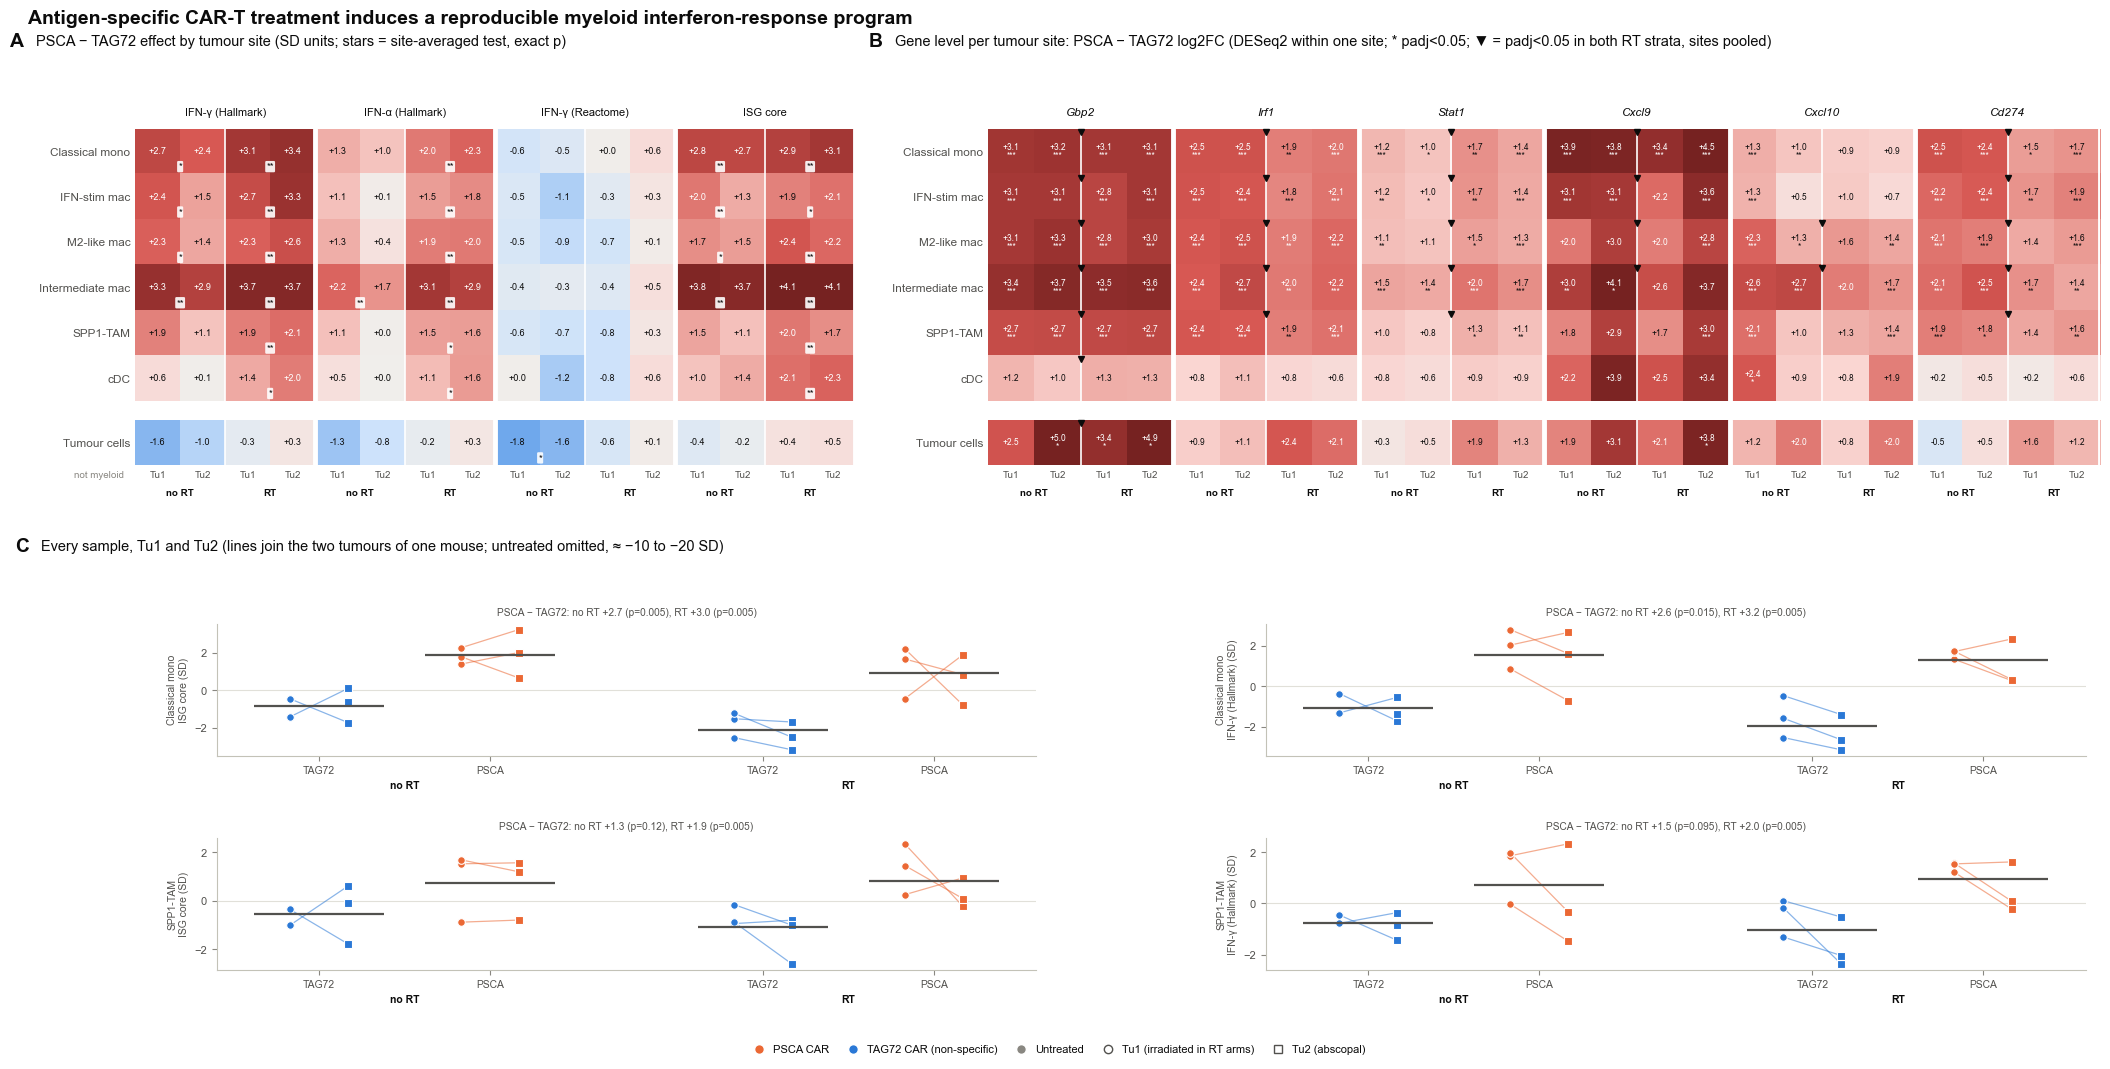

per-site estimates: smallest attainable exact p within one site is 0.10 (3 v 3 tumours -> 0.10, 3 v 2 -> 0.20), so significance stays with the site-averaged stratum test


In [5]:
MYE = ["Classical_Mono", "IFN_stimulated_Mac", "M2_like_Mac", "Intermediate_Mac", "SPP1_TAM", "cDC"]
IFNP = ["IFNG_Hallmark", "IFNA_Hallmark", "IFNG_Reactome", "ISG_core"]
SC = {g: group_scores(g) for g in MYE + ["Cancer_cell", "NK", "CD8_T", "cytotoxic_lymph", "N1_like_Neu"]}
# per-site columns: (stratum label, PSCA arm, TAG72 arm) x site. Tu1 = irradiated in the RT stratum, Tu2 = abscopal.
STRATA2 = [("no RT", "CyPSCA", "CyT72"), ("RT", "RTCyPSCA", "RTCyT72")]
COLS2 = [(st, site) for st, _, _ in STRATA2 for site in (1, 2)]


def effects_table(groups, programs, eff):
    rows = []
    for g in groups:
        S, M = SC[g]; sdw = sd_within(S, M)
        for p_ in programs:
            if p_ not in S: continue
            e = effect(S[p_], M, eff, sdw[p_])
            r = dict(group=g, program=p_, effect=eff)
            for lab in [l for l, _ in EFFECTS[eff]] + ["pooled", "CARxRT"]:
                if lab in e: r.update({f"{lab}_{k}": e[lab][k] for k in ["est", "lo", "hi", "p"]})
            r.update(replicated=e.get("replicated", False), sign_agree=e.get("sign_agree"),
                     loo_flips=e.get("loo", (np.nan,))[0], loo_n=e.get("loo", (np.nan, np.nan))[1])
            rows.append(r)
    return pd.DataFrame(rows)


def per_site_table(groups, programs):
    """PSCA - TAG72 within one site of one RT stratum (the '_cell' of the stratum estimate), SD units, exact p."""
    rows = []
    for g in groups:
        S, M = SC[g]; sdw = sd_within(S, M)
        for p_ in programs:
            if p_ not in S: continue
            for st, A, B in STRATA2:
                for site in (1, 2):
                    c = _cell(S[p_], M, A, B, site)
                    r = dict(group=g, program=p_, stratum=st, site=site)
                    if c is not None:
                        r.update(est=c["d"] / sdw[p_], p=_p(c["null"]), n=f"{c['nA']}v{c['nB']}")
                    rows.append(r)
    return pd.DataFrame(rows)


E2 = effects_table(MYE + ["Cancer_cell"], IFNP, "PSCA")
E2.to_csv(OUT/"fig2_ifn_program_effects.csv", index=False)
E2S = per_site_table(MYE + ["Cancer_cell"], IFNP)
E2S.to_csv(OUT/"fig2_ifn_program_effects_by_site.csv", index=False)


def site_heatmap(ax, M, vmax, star_mat=None, fs=6.5):
    """annotated heatmap with 4 columns per item (no RT Tu1, Tu2 | RT Tu1, Tu2): thick white line between items,
    thin line between strata."""
    annotated_heatmap(ax, M, vmax=vmax, star_mat=star_mat, fs=fs)
    for x in np.arange(3.5, M.shape[1], 4): ax.axvline(x, color="white", lw=3.5)
    for x in np.arange(1.5, M.shape[1], 4): ax.axvline(x, color="white", lw=1.2)


def site_xaxis(ax, n_items, show):
    ax.set_xticks(range(4 * n_items))
    ax.set_xticklabels(["Tu1", "Tu2"] * 2 * n_items if show else [], fontsize=7)
    if show:
        for j in range(n_items):
            for k_, st in enumerate(["no RT", "RT"]):
                under_label(ax, 4 * j + 2 * k_ + 0.5, st, 1, fs=7, bold=True)


def f2A(sf):
    gs = sf.add_gridspec(2, 1, height_ratios=[len(MYE), 1], left=0.15, right=0.99, top=0.80, bottom=0.12, hspace=0.12)
    cols = [(p_, st, site) for p_ in IFNP for st, site in COLS2]
    for k, rows in enumerate([MYE, ["Cancer_cell"]]):
        ax = sf.add_subplot(gs[k])
        cell = lambda g, p_, st, site, c: E2S[(E2S.group == g) & (E2S.program == p_) & (E2S.stratum == st)
                                              & (E2S.site == site)][c].squeeze()
        M = pd.DataFrame([[cell(g, p_, st, site, "est") for p_, st, site in cols] for g in rows], index=rows, dtype=float)
        site_heatmap(ax, M, vmax=4)
        # the stratum test (site-averaged, exact p) is shown once per Tu1 / Tu2 pair
        for i, g in enumerate(rows):
            for j0 in range(0, len(cols), 2):
                p_, st, _ = cols[j0]
                pst = E2[(E2.group == g) & (E2.program == p_)][f"{st}_p"].squeeze()
                s_ = stars(pst) if pd.notna(pst) else ""
                if s_:
                    ax.text(j0 + 0.5, i + 0.34, s_, ha="center", va="center", fontsize=7, color=INK,
                            bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.9))
        ax.set_yticklabels([NAME[g] for g in rows], fontsize=8.5)
        site_xaxis(ax, len(IFNP), show=(k == 1))
        if k == 0:
            for j, p_ in enumerate(IFNP):
                ax.text(4 * j + 1.5, -0.75, NAME[p_], ha="center", va="bottom", fontsize=8, color=INK)
        else:
            ax.text(-0.75, 0.62, "not myeloid", fontsize=7, color=MUTED, ha="right", va="top")
    panel_label(sf, "A", "PSCA − TAG72 effect by tumour site (SD units; stars = site-averaged test, exact p)")


def de_matrix(groups, genes, contrasts):
    """log2FC matrix (groups x gene|contrast, gene-major), padj stars, and 'significant in every contrast'."""
    cols = [f"{g}|{c}" for g in genes for c in contrasts]
    M = pd.DataFrame(np.nan, index=groups, columns=cols)
    St = pd.DataFrame("", index=groups, columns=cols); Rep = pd.DataFrame(False, index=groups, columns=genes)
    for grp in groups:
        for g in genes:
            r = DE[(DE.group == grp) & (DE.gene == g)].set_index("contrast")
            for c in contrasts:
                if c in r.index:
                    M.loc[grp, f"{g}|{c}"] = r.loc[c, "log2FoldChange"]
                    St.loc[grp, f"{g}|{c}"] = stars(r.loc[c, "padj"]) if pd.notna(r.loc[c, "padj"]) else ""
            if all(c in r.index for c in contrasts):
                ok = [r.loc[c, "padj"] < 0.05 if pd.notna(r.loc[c, "padj"]) else False for c in contrasts]
                Rep.loc[grp, g] = all(ok) and len({np.sign(r.loc[c, "log2FoldChange"]) for c in contrasts}) == 1
    return M, St, Rep


GENES2 = ["Gbp2", "Irf1", "Stat1", "Cxcl9", "Cxcl10", "Cd274"]

# per-site gene-level fits: DESeq2 '~ car' on the tumours of one site and one RT stratum (3 v 2-3 tumours), cached
DE_SITE_FILE = OUT/"fig2_persite_de.parquet"
if DE_SITE_FILE.exists():
    DES = pd.read_parquet(DE_SITE_FILE)
else:
    from pydeseq2.dds import DeseqDataSet
    from pydeseq2.ds import DeseqStats
    from pydeseq2.default_inference import DefaultInference
    _inf, rows_, t0_ = DefaultInference(n_cpus=8), [], time.time()
    for grp in MYE + ["Cancer_cell"]:
        for st, A, B in STRATA2:
            for site in (1, 2):
                d = PBM[(PBM.group == grp) & (PBM.n_cells >= MIN_CELLS) & PBM.arm.isin([A, B]) & (PBM.site == site)]
                if (d.arm == A).sum() < 2 or (d.arm == B).sum() < 2: continue
                X = PB.loc[d.index]
                keep = (((X > 0).sum(0) >= 3) & (X.sum(0) >= 10 * len(X))) | (X.columns.isin(GENES2) & ((X > 0).sum(0) >= 2))
                X = X.loc[:, keep]
                md = pd.DataFrame({"car": pd.Categorical(np.where(d.arm == A, "PSCA", "TAG72"), ["TAG72", "PSCA"])},
                                  index=X.index)
                dds = DeseqDataSet(counts=X, metadata=md, design="~ car", inference=_inf, quiet=True); dds.deseq2()
                stt = DeseqStats(dds, contrast=["car", "PSCA", "TAG72"], inference=_inf, quiet=True); stt.summary()
                r = stt.results_df.reindex([g for g in GENES2 if g in stt.results_df.index])   # padj = BH over the whole fit
                rows_.append(r.assign(group=grp, stratum=st, site=site,
                                      n=f"{(d.arm == A).sum()}v{(d.arm == B).sum()}").reset_index(names="gene"))
    DES = pd.concat(rows_, ignore_index=True); DES.to_parquet(DE_SITE_FILE)
    print(f"per-site DESeq2: {DES.groupby(['group', 'stratum', 'site']).ngroups} fits in {time.time() - t0_:.0f}s")
DES.to_csv(OUT/"fig2_gene_de_by_site.csv", index=False)


def f2B(sf):
    gs = sf.add_gridspec(2, 1, height_ratios=[len(MYE), 1], left=0.10, right=0.995, top=0.80, bottom=0.12, hspace=0.12)
    cols = [(g, st, site) for g in GENES2 for st, site in COLS2]
    for k, rows in enumerate([MYE, ["Cancer_cell"]]):
        ax = sf.add_subplot(gs[k])
        _, _, Rep = de_matrix(rows, GENES2, ["PSCA_nonRT", "PSCA_RT"])     # site-pooled fits, for the triangle
        get = lambda grp, g, st, site: DES[(DES.group == grp) & (DES.gene == g) & (DES.stratum == st) & (DES.site == site)]
        M = pd.DataFrame([[get(grp, g, st, site).log2FoldChange.squeeze() if len(get(grp, g, st, site)) else np.nan
                           for g, st, site in cols] for grp in rows], index=rows, dtype=float)
        St = pd.DataFrame([[stars(get(grp, g, st, site).padj.squeeze()) if len(get(grp, g, st, site))
                            and pd.notna(get(grp, g, st, site).padj.squeeze()) else "" for g, st, site in cols]
                           for grp in rows], index=rows)
        site_heatmap(ax, M, vmax=4, star_mat=St, fs=6)
        ax.set_yticklabels([NAME[g] for g in rows], fontsize=8.5)
        for i, grp in enumerate(rows):
            for j, g in enumerate(GENES2):
                if Rep.loc[grp, g]: ax.plot(4 * j + 1.5, i - 0.42, marker="v", ms=4.5, color=INK, clip_on=False)
        site_xaxis(ax, len(GENES2), show=(k == 1))
        if k == 0:
            for j, g in enumerate(GENES2):
                ax.text(4 * j + 1.5, -0.75, g, ha="center", va="bottom", fontsize=8.5, style="italic", color=INK)
    panel_label(sf, "B", "Gene level per tumour site: PSCA − TAG72 log2FC (DESeq2 within one site; * padj<0.05; "
                         "▼ = padj<0.05 in both RT strata, sites pooled)")


def paired_strip(ax, v, M, ylabel="", notx=True):
    """Facets (untreated |) no RT | RT on one axis; TAG72 / PSCA within; Tu1/Tu2 joined per mouse."""
    X = {"NoTx": 0.0, "CyT72": 1.6, "CyPSCA": 2.6, "RTCyT72": 4.2, "RTCyPSCA": 5.2}
    if not notx: X.pop("NoTx")
    for arm, x0 in X.items():
        d = M[M.arm == arm]
        for mouse, g in d.groupby("mouse"):
            pts = {int(s): v.get(i, np.nan) for i, s in g.site.items()}
            if 1 in pts and 2 in pts and np.isfinite(pts[1]) and np.isfinite(pts[2]):
                ax.plot([x0 - 0.17, x0 + 0.17], [pts[1], pts[2]], color=CAR_COL[CAR_OF[arm]], lw=0.9, alpha=0.55, zorder=2)
        for site, off in [(1, -0.17), (2, 0.17)]:
            vals = v[[i for i in d.index[d.site == site] if i in v.index]]
            dots(ax, np.full(len(vals), x0 + off), vals.values, arm, site, s=30)
        mean_tick(ax, x0, v[[i for i in d.index if i in v.index]].mean(), w=0.38, color=INK2)
    ax.set_xticks(list(X.values()))
    ax.set_xticklabels([{"NoTx": "Untr."}.get(a, "PSCA" if "PSCA" in a else "TAG72") for a in X], fontsize=7.5)
    for lab, xm in [("no RT", 2.1), ("RT", 4.7)]: under_label(ax, xm, lab, 1, bold=True)
    ax.axhline(0, color=GRID, lw=0.8, zorder=0); ax.set_ylabel(ylabel, fontsize=7.5)
    ax.set_xlim(min(X.values()) - 0.6, 5.8)


def f2C(sf):
    gs = sf.add_gridspec(2, 2, left=0.10, right=0.99, top=0.82, bottom=0.12, wspace=0.28, hspace=0.62)
    for r_, grp in enumerate(["Classical_Mono", "SPP1_TAM"]):
        S, M = SC[grp]; sdw = sd_within(S, M)
        for c_, prog in enumerate(["ISG_core", "IFNG_Hallmark"]):
            ax = sf.add_subplot(gs[r_, c_])
            paired_strip(ax, S[prog] / sdw[prog], M, ylabel=f"{NAME[grp]}\n{NAME[prog]} (SD)", notx=False)
            e = E2[(E2.group == grp) & (E2.program == prog)].iloc[0]
            ax.set_title(f"PSCA − TAG72: no RT {e['no RT_est']:+.1f} ({fmt_p(e['no RT_p'])}), "
                         f"RT {e['RT_est']:+.1f} ({fmt_p(e['RT_p'])})", fontsize=7.3, color=INK2)
    panel_label(sf, "C", "Every sample, Tu1 and Tu2 (lines join the two tumours of one mouse; untreated omitted, ≈ −10 to −20 SD)")


fig2 = plt.figure(figsize=(21, 10))
top2, bot2 = fig2.subfigures(2, 1, height_ratios=[1.0, 1.0], hspace=0.02)
a2, b2 = top2.subfigures(1, 2, width_ratios=[1.0, 1.45])
f2A(a2); f2B(b2); f2C(bot2)
legend_car_site(fig2)
fig2.suptitle("Antigen-specific CAR-T treatment induces a reproducible myeloid interferon-response program",
              x=0.01, y=1.02, ha="left", fontsize=14, fontweight="bold")
save(fig2, "Figure2_interferon"); plt.show()
for fn, sz, nm in [(f2A, (9, 4.8), "Fig2A"), (f2B, (13, 4.8), "Fig2B"), (f2C, (10, 5.6), "Fig2C")]:
    save_panel(fn, sz, nm)
n_floor = E2S.dropna(subset=["p"]).p.min()
print(f"per-site estimates: smallest attainable exact p within one site is {n_floor:.2f} "
      f"(3 v 3 tumours -> 0.10, 3 v 2 -> 0.20), so significance stays with the site-averaged stratum test")

## Figure 3 — Myeloid antigen-presentation machinery

**Title:** *PSCA CAR-T therapy induces MHC-I and MHC-II antigen-processing programs in tumour-associated
myeloid cells* — the claim is increased **machinery**, not increased presentation to T cells.
Tumour-cell MHC-II is excluded (ambient macrophage RNA); its QC is Figure S3.

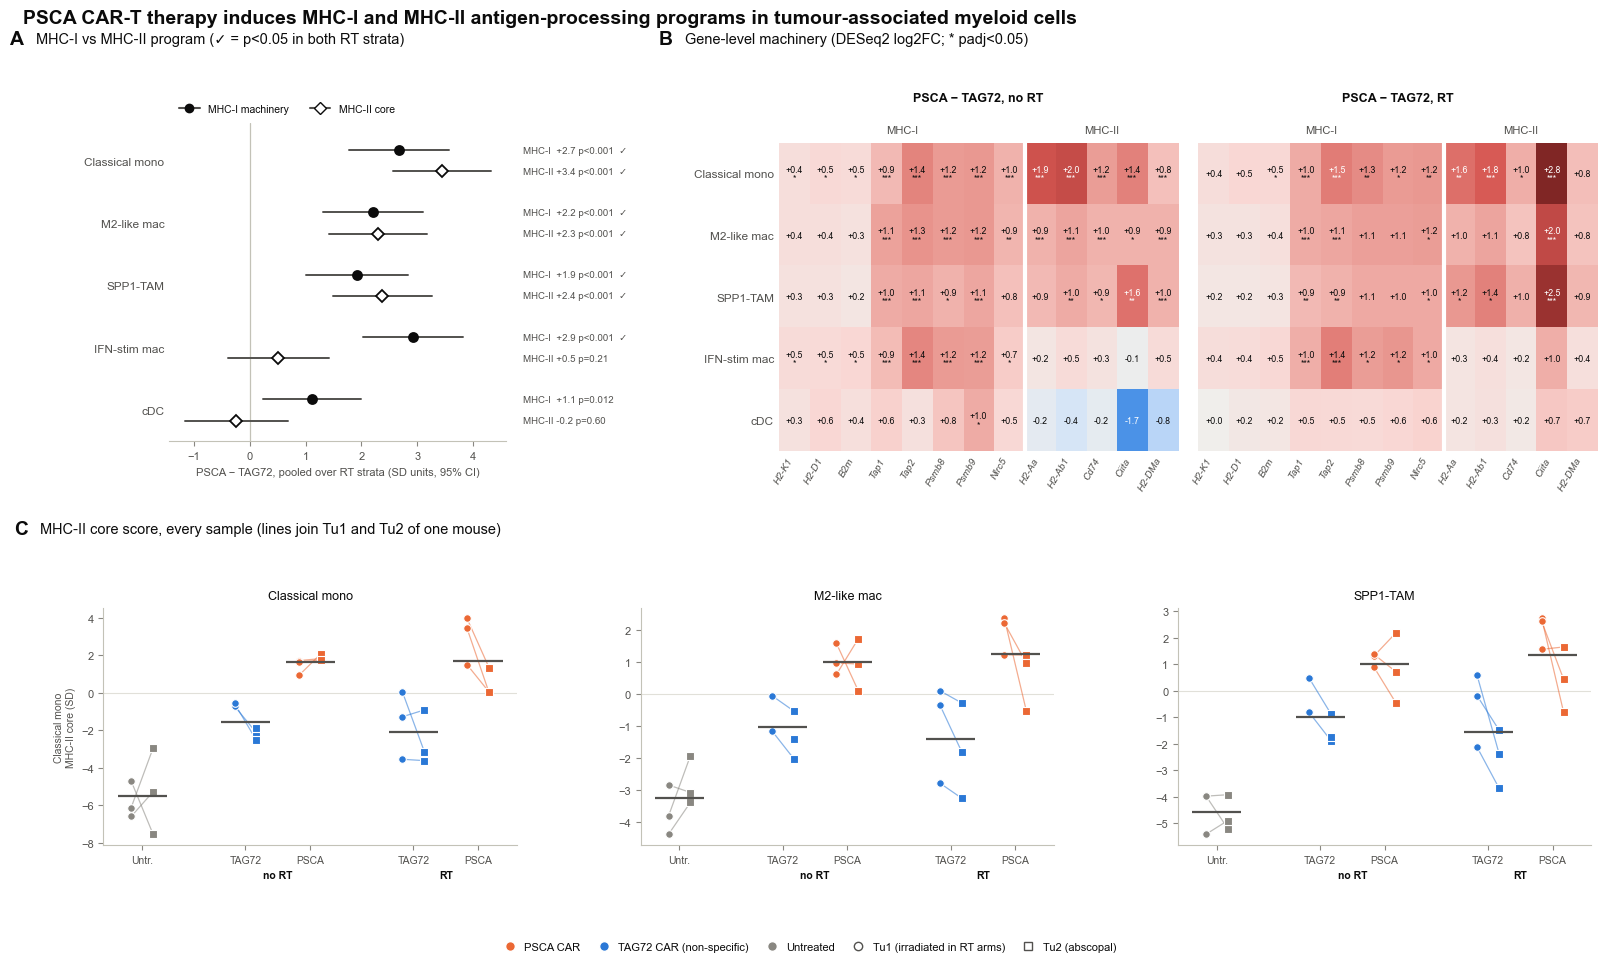

In [6]:
MHC_POPS = ["Classical_Mono", "M2_like_Mac", "SPP1_TAM", "IFN_stimulated_Mac", "cDC"]
E3 = effects_table(MHC_POPS, ["MHC_I_machinery", "MHC_II_core"], "PSCA")
E3.to_csv(OUT/"fig3_mhc_program_effects.csv", index=False)


def f3A(sf):
    ax = sf.add_axes([0.25, 0.14, 0.52, 0.66])
    for i, grp in enumerate(MHC_POPS):
        for j, (p_, mk, fill) in enumerate([("MHC_I_machinery", "o", INK), ("MHC_II_core", "D", "white")]):
            r = E3[(E3.group == grp) & (E3.program == p_)].iloc[0]; y = i + (j - 0.5) * 0.34
            ax.plot([r.pooled_lo, r.pooled_hi], [y, y], color=INK2, lw=1.4)
            ax.plot(r.pooled_est, y, marker=mk, ms=6.5, mfc=fill, mec=INK, mew=1.3, ls="")
            ax.text(1.05, y, f"{'MHC-I ' if j == 0 else 'MHC-II'} {r.pooled_est:+.1f} {fmt_p(r.pooled_p)}"
                    f"{'  ✓' if r.replicated else ''}", transform=mpl.transforms.blended_transform_factory(ax.transAxes, ax.transData),
                    fontsize=7, va="center", color=INK2)
    ax.axvline(0, color=AXIS, lw=0.9, zorder=0)
    ax.set_yticks(range(len(MHC_POPS))); ax.set_yticklabels([NAME[g] for g in MHC_POPS], fontsize=8.5)
    ax.set_ylim(len(MHC_POPS) - 0.5, -0.6); ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
    ax.set_xlabel("PSCA − TAG72, pooled over RT strata (SD units, 95% CI)", fontsize=8)
    ax.legend(handles=[Line2D([], [], marker="o", ls="-", color=INK2, mfc=INK, mec=INK, ms=6, label="MHC-I machinery"),
                       Line2D([], [], marker="D", ls="-", color=INK2, mfc="white", mec=INK, ms=6, label="MHC-II core")],
              loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=7.5)
    panel_label(sf, "A", "MHC-I vs MHC-II program (✓ = p<0.05 in both RT strata)")


MHC1 = ["H2-K1", "H2-D1", "B2m", "Tap1", "Tap2", "Psmb8", "Psmb9", "Nlrc5"]
MHC2 = ["H2-Aa", "H2-Ab1", "Cd74", "Ciita", "H2-DMa"]


def f3B(sf):
    gs = sf.add_gridspec(1, 2, left=0.13, right=0.99, top=0.76, bottom=0.12, wspace=0.05)
    for k, (c, lab) in enumerate([("PSCA_nonRT", "no RT"), ("PSCA_RT", "RT")]):
        ax = sf.add_subplot(gs[k])
        M, St, _ = de_matrix(MHC_POPS, MHC1 + MHC2, [c])
        M.columns = [c_.split("|")[0] for c_ in M.columns]; St.columns = M.columns
        annotated_heatmap(ax, M, vmax=3, star_mat=St, fs=6.3)
        ax.axvline(len(MHC1) - 0.5, color="white", lw=3)
        ax.set_xticklabels(M.columns, rotation=60, ha="right", fontsize=7.2, style="italic")
        ax.set_yticklabels([NAME[g] for g in MHC_POPS] if k == 0 else [], fontsize=8.5)
        ax.set_title(f"PSCA − TAG72, {lab}", fontsize=9, pad=30, fontweight="bold")
        ax.text((len(MHC1) - 1) / 2, -0.62, "MHC-I", ha="center", va="bottom", fontsize=8, color=INK2)
        ax.text(len(MHC1) + (len(MHC2) - 1) / 2, -0.62, "MHC-II", ha="center", va="bottom", fontsize=8, color=INK2)
    panel_label(sf, "B", "Gene-level machinery (DESeq2 log2FC; * padj<0.05)")


def f3C(sf):
    gs = sf.add_gridspec(1, 3, left=0.06, right=0.99, top=0.78, bottom=0.20, wspace=0.3)
    for k, grp in enumerate(["Classical_Mono", "M2_like_Mac", "SPP1_TAM"]):
        ax = sf.add_subplot(gs[k]); S, M = SC[grp]
        paired_strip(ax, S["MHC_II_core"] / sd_within(S, M)["MHC_II_core"], M, ylabel=f"{NAME[grp]}\nMHC-II core (SD)" if k == 0 else "")
        ax.set_title(NAME[grp], fontsize=9)
    panel_label(sf, "C", "MHC-II core score, every sample (lines join Tu1 and Tu2 of one mouse)")


fig3 = plt.figure(figsize=(16, 9.0))
top3, bot3 = fig3.subfigures(2, 1, height_ratios=[1.0, 0.85], hspace=0.02)
a3, b3 = top3.subfigures(1, 2, width_ratios=[0.85, 1.25]); f3A(a3); f3B(b3); f3C(bot3)
legend_car_site(fig3)
fig3.suptitle("PSCA CAR-T therapy induces MHC-I and MHC-II antigen-processing programs in tumour-associated myeloid cells",
              x=0.01, y=1.02, ha="left", fontsize=14, fontweight="bold")
save(fig3, "Figure3_antigen_presentation"); plt.show()
for fn, sz, nm in [(f3A, (7.5, 4.4), "Fig3A"), (f3B, (9.5, 4.4), "Fig3B"), (f3C, (14, 4.0), "Fig3C")]:
    save_panel(fn, sz, nm)

### Figure S3 — QC: tumour-cell MHC-II is macrophage RNA

**A** median intrinsic fraction per gene in the tumour pseudobulk (1 = the tumour's own transcript;
from macrophage-exclusive markers, `mhcCytotoxExhaustion/01 §4`). **B** the CAR × RT interaction on
tumour MHC genes in the full tumour pseudobulk vs tumour cells with **zero** macrophage-marker reads.

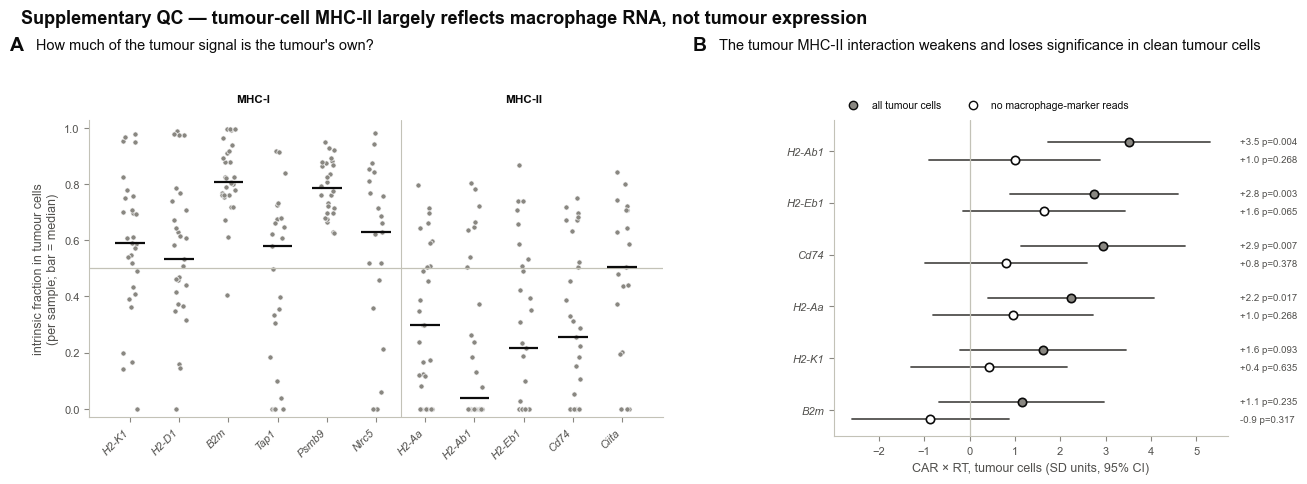

In [7]:
AMB = pd.read_csv(SRC/"q1_ambient_estimate.csv"); CL = pd.read_csv(SRC/"q1_tumour_clean_vs_rest.csv").set_index("sample")
TUM = ["H2-K1", "H2-D1", "B2m", "Tap1", "Psmb9", "Nlrc5", "H2-Aa", "H2-Ab1", "H2-Eb1", "Cd74", "Ciita"]


def fS3A(sf):
    ax = sf.add_axes([0.12, 0.2, 0.84, 0.62])
    d = AMB[(AMB.compartment == "Cancer_cell") & AMB.gene.isin(TUM)]
    for i, g in enumerate(TUM):
        v = d[d.gene == g].intrinsic_frac.dropna()
        ax.scatter(np.full(len(v), i) + np.random.default_rng(i).uniform(-0.15, 0.15, len(v)), v, s=14,
                   color=MUTED, edgecolor="white", lw=0.5, zorder=2)
        mean_tick(ax, i, v.median(), w=0.3)
    ax.axhline(0.5, color=AXIS, lw=0.9); ax.axvline(5.5, color=AXIS, lw=0.8)
    ax.set_xticks(range(len(TUM))); ax.set_xticklabels(TUM, rotation=45, ha="right", style="italic", fontsize=8)
    ax.set_ylim(-0.03, 1.03); ax.set_ylabel("intrinsic fraction in tumour cells\n(per sample; bar = median)")
    ax.text(2.5, 1.06, "MHC-I", ha="center", fontweight="bold", fontsize=8.5, transform=mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes))
    ax.text(8.0, 1.06, "MHC-II", ha="center", fontweight="bold", fontsize=8.5, transform=mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes))
    panel_label(sf, "A", "How much of the tumour signal is the tumour's own?")


def fS3B(sf):
    ax = sf.add_axes([0.2, 0.16, 0.55, 0.66])
    tumk = PBM[(PBM.group == "Cancer_cell") & (PBM.n_cells >= MIN_CELLS)]
    meta = tumk.set_index("sample")[["arm", "site", "mouse"]]
    rows = []
    for g in ["H2-Ab1", "H2-Eb1", "Cd74", "H2-Aa", "H2-K1", "B2m"]:
        full = pd.Series(L.loc[tumk.index, g].values, index=tumk["sample"].values)
        clean = CL.get(f"{g}_clean")
        for lab, v in [("all tumour cells", full), ("clean tumour cells", clean)]:
            if v is None: continue
            mt = meta.loc[[s for s in v.index if s in meta.index]]
            vv = v.loc[mt.index]
            sdw = vv.to_frame("x").join(mt).query("arm != 'NoTx'").groupby(["arm", "site"]).x.var().mean() ** 0.5
            e = effect(vv, mt, "PSCA", sdw)
            if "CARxRT" in e: rows.append(dict(gene=g, set=lab, **e["CARxRT"]))
    R = pd.DataFrame(rows); R.to_csv(OUT/"figS3_tumour_mhc_carxrt.csv", index=False)
    for i, g in enumerate(R.gene.unique()):
        for j, (lab, fill) in enumerate([("all tumour cells", MUTED), ("clean tumour cells", "white")]):
            r = R[(R.gene == g) & (R.set == lab)]
            if r.empty: continue
            r = r.iloc[0]; y = i + (j - 0.5) * 0.34
            ax.plot([r.lo, r.hi], [y, y], color=INK2, lw=1.3)
            ax.plot(r.est, y, marker="o", ms=6, mfc=fill, mec=INK, mew=1.2, ls="")
            ax.text(1.03, y, f"{r.est:+.1f} p={r.p:.3f}", transform=mpl.transforms.blended_transform_factory(ax.transAxes, ax.transData),
                    fontsize=7, va="center", color=INK2)
    ax.axvline(0, color=AXIS, lw=0.9); ax.set_yticks(range(R.gene.nunique()))
    ax.set_yticklabels(R.gene.unique(), style="italic"); ax.set_ylim(R.gene.nunique() - 0.5, -0.6)
    ax.set_xlabel("CAR × RT, tumour cells (SD units, 95% CI)")
    ax.legend(handles=[Line2D([], [], marker="o", ls="", mfc=MUTED, mec=INK, label="all tumour cells"),
                       Line2D([], [], marker="o", ls="", mfc="white", mec=INK, label="no macrophage-marker reads")],
              loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, fontsize=7.5)
    panel_label(sf, "B", "The tumour MHC-II interaction weakens and loses significance in clean tumour cells")


figS3 = plt.figure(figsize=(14, 4.8)); s1, s2 = figS3.subfigures(1, 2, width_ratios=[1, 1.05])
fS3A(s1); fS3B(s2)
figS3.suptitle("Supplementary QC — tumour-cell MHC-II largely reflects macrophage RNA, not tumour expression",
               x=0.01, y=1.05, ha="left", fontsize=13, fontweight="bold")
save(figS3, "FigureS3_tumour_MHC_QC"); plt.show()

## Figure 4 — PSCA, direct RT and indirect RT compared

**Title:** *Antigen-specific CAR-T effects are more consistently detected than radiotherapy effects*
— at this sampling point comparatively few RT effects meet the criteria; that does not show RT was
biologically inactive or that smaller effects are absent.

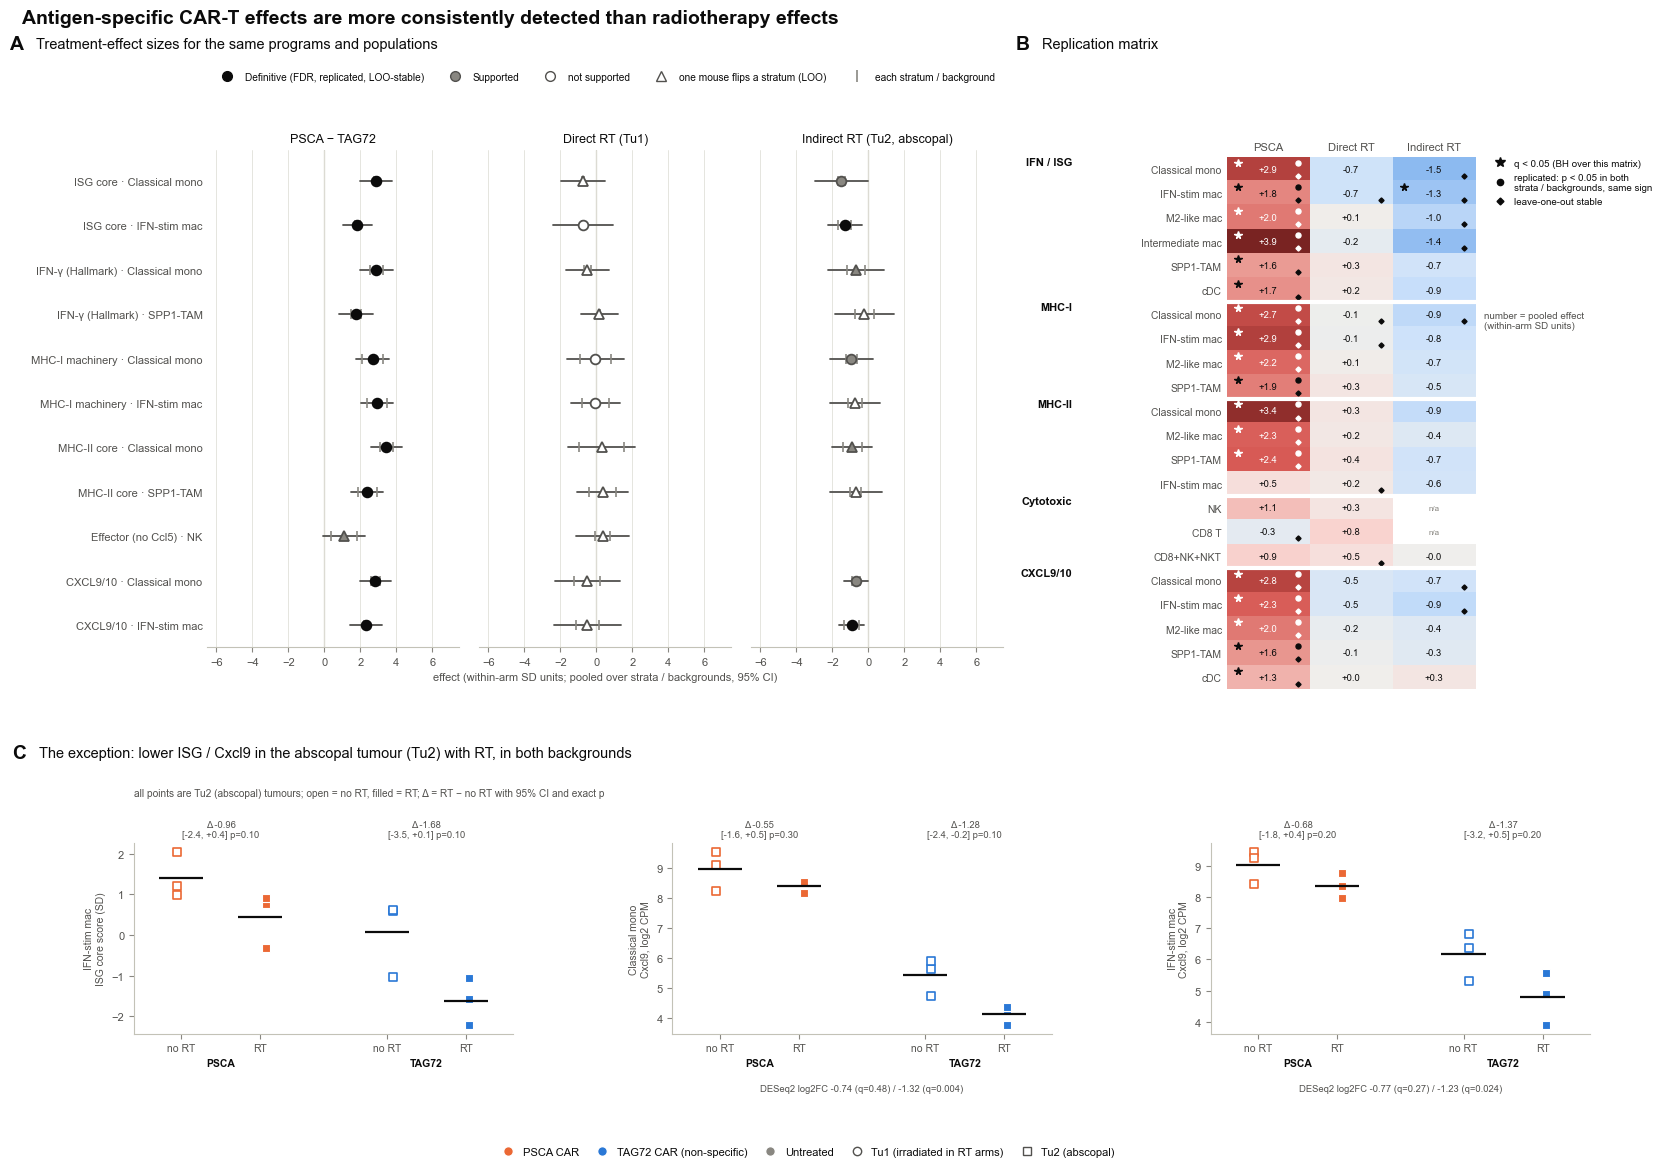

In [8]:
F4 = [("ISG_core", "Classical_Mono"), ("ISG_core", "IFN_stimulated_Mac"), ("IFNG_Hallmark", "Classical_Mono"),
      ("IFNG_Hallmark", "SPP1_TAM"), ("MHC_I_machinery", "Classical_Mono"), ("MHC_I_machinery", "IFN_stimulated_Mac"),
      ("MHC_II_core", "Classical_Mono"), ("MHC_II_core", "SPP1_TAM"), ("cyto_effector_noCcl5", "NK"),
      ("CXCR3_ligands", "Classical_Mono"), ("CXCR3_ligands", "IFN_stimulated_Mac")]
EFF3 = ["PSCA", "direct RT", "indirect RT"]


def tier_of(prog, grp, eff):
    if prog == "CXCR3_ligands":
        d = LEDC[(LEDC.gene.isin(["Cxcl9", "Cxcl10"])) & (LEDC.group == grp) & (LEDC.effect == eff)]
        order = ["Definitive", "Supported", "Suggestive", "No evidence"]
        ts = [t for t in d.observed_transcriptional_change if t in order]
        t = min(ts, key=order.index) if ts else "No evidence"
        return t
    d = LEDP[(LEDP.program == prog) & (LEDP.group == grp) & (LEDP.effect == eff)]
    return d.tier.iloc[0] if len(d) else "No evidence"


R4 = []
for prog, grp in F4:
    S, M = SC[grp]; sdw = sd_within(S, M)
    for eff in EFF3:
        e = effect(S[prog], M, eff, sdw[prog]); labs = [l for l, _ in EFFECTS[eff]]
        R4.append(dict(program=prog, group=grp, effect=eff, tier=tier_of(prog, grp, eff),
                       **{f"{s}_{k}": e[s][k] for s in labs + ["pooled"] if s in e for k in ["est", "lo", "hi", "p"]},
                       s1=e.get(labs[0], {}).get("est", np.nan), s2=e.get(labs[1], {}).get("est", np.nan),
                       replicated=e.get("replicated", False), loo_flips=e.get("loo", (np.nan,))[0]))
R4 = pd.DataFrame(R4); R4.to_csv(OUT/"fig4_three_way_effects.csv", index=False)
TIER_STYLE = {"Definitive": (INK, INK), "Supported": (MUTED, INK2)}


def f4A(sf):
    gs = sf.add_gridspec(1, 3, left=0.2, right=0.99, top=0.83, bottom=0.12, wspace=0.08)
    for k, eff in enumerate(EFF3):
        ax = sf.add_subplot(gs[k])
        for i, (prog, grp) in enumerate(F4):
            r = R4[(R4.program == prog) & (R4.group == grp) & (R4.effect == eff)].iloc[0]
            if not np.isfinite(r.get("pooled_est", np.nan)): continue
            fill, edge = TIER_STYLE.get(r.tier, ("white", INK2))
            ax.plot([r.pooled_lo, r.pooled_hi], [i, i], color=INK2, lw=1.3, zorder=2)
            for s_ in ["s1", "s2"]:
                ax.plot(r[s_], i, marker="|", ms=7, mew=1.2, color=MUTED, zorder=2)
            ax.plot(r.pooled_est, i, marker="o" if r.loo_flips == 0 else "^", ms=7, mfc=fill, mec=edge, mew=1.3, ls="", zorder=3)
        ax.axvline(0, color=AXIS, lw=0.9, zorder=0); ax.set_xlim(-6.5, 7.5)
        ax.set_ylim(len(F4) - 0.5, -0.7); ax.set_title({"PSCA": "PSCA − TAG72", "direct RT": "Direct RT (Tu1)",
                                                         "indirect RT": "Indirect RT (Tu2, abscopal)"}[eff], fontsize=9)
        ax.set_yticks(range(len(F4)))
        ax.set_yticklabels([f"{NAME[p_]} · {NAME[g]}" for p_, g in F4] if k == 0 else [], fontsize=8)
        ax.tick_params(axis="y", length=0); ax.spines["left"].set_visible(False)
        ax.xaxis.grid(True); ax.set_axisbelow(True)
        if k == 1: ax.set_xlabel("effect (within-arm SD units; pooled over strata / backgrounds, 95% CI)", fontsize=8)
    h = [Line2D([], [], marker="o", ls="", mfc=INK, mec=INK, ms=7, label="Definitive (FDR, replicated, LOO-stable)"),
         Line2D([], [], marker="o", ls="", mfc=MUTED, mec=INK2, ms=7, label="Supported"),
         Line2D([], [], marker="o", ls="", mfc="white", mec=INK2, ms=7, label="not supported"),
         Line2D([], [], marker="^", ls="", mfc="white", mec=INK2, ms=7, label="one mouse flips a stratum (LOO)"),
         Line2D([], [], marker="|", ls="", color=MUTED, ms=8, mew=1.2, label="each stratum / background")]
    sf.legend(handles=h, loc="upper left", bbox_to_anchor=(0.2, 0.955), ncol=5, frameon=False, fontsize=7.3)
    panel_label(sf, "A", "Treatment-effect sizes for the same programs and populations")


MAT = [("IFN / ISG", "ISG_core", g) for g in ["Classical_Mono", "IFN_stimulated_Mac", "M2_like_Mac", "Intermediate_Mac", "SPP1_TAM", "cDC"]] + \
      [("MHC-I", "MHC_I_machinery", g) for g in ["Classical_Mono", "IFN_stimulated_Mac", "M2_like_Mac", "SPP1_TAM"]] + \
      [("MHC-II", "MHC_II_core", g) for g in ["Classical_Mono", "M2_like_Mac", "SPP1_TAM", "IFN_stimulated_Mac"]] + \
      [("Cytotoxic", "cyto_effector_noCcl5", g) for g in ["NK", "CD8_T", "cytotoxic_lymph"]] + \
      [("CXCL9/10", "CXCR3_ligands", g) for g in ["Classical_Mono", "IFN_stimulated_Mac", "M2_like_Mac", "SPP1_TAM", "cDC"]]
RM = []
for fam_, prog, grp in MAT:
    S, M = SC[grp]
    if prog not in S: continue
    for eff in EFF3:
        e = effect(S[prog], M, eff, sd_within(S, M)[prog])
        RM.append(dict(family=fam_, program=prog, group=grp, effect=eff, est=e.get("pooled", {}).get("est", np.nan),
                       p=e.get("pooled", {}).get("p", np.nan), replicated=e.get("replicated", False),
                       sign_agree=e.get("sign_agree"), loo=e.get("loo", (np.nan,))[0]))
RM = pd.DataFrame(RM)
ok = RM.p.notna(); RM["q"] = np.nan; RM.loc[ok, "q"] = multipletests(RM.p[ok], method="fdr_bh")[1]
RM.to_csv(OUT/"fig4_replication_matrix.csv", index=False)


def f4B(sf):
    ax = sf.add_axes([0.36, 0.06, 0.42, 0.76])
    rows = list(dict.fromkeys(zip(RM.family, RM.group)))
    E = pd.DataFrame([[RM[(RM.family == f_) & (RM.group == g) & (RM.effect == e)].est.squeeze() for e in EFF3] for f_, g in rows],
                     dtype=float)
    norm = annotated_heatmap(ax, E, vmax=4, fs=6.8)
    for i, (f_, g) in enumerate(rows):
        for j, e in enumerate(EFF3):
            r = RM[(RM.family == f_) & (RM.group == g) & (RM.effect == e)]
            if r.empty: continue
            r = r.iloc[0]; col = text_color(DIV(norm(r.est))) if np.isfinite(r.est) else INK
            if r.replicated: ax.plot(j + 0.36, i - 0.27, marker="o", ms=3.6, color=col)
            if pd.notna(r.q) and r.q < 0.05: ax.plot(j - 0.36, i - 0.27, marker="*", ms=5.5, color=col)
            if r.loo == 0 and np.isfinite(r.est): ax.plot(j + 0.36, i + 0.27, marker="D", ms=2.6, color=col)
    ax.set_xticklabels(["PSCA", "Direct RT", "Indirect RT"], fontsize=8); ax.xaxis.tick_top()
    ax.set_yticklabels([f"{NAME[g]}" for _, g in rows], fontsize=7.5)
    prev = None
    for i, (f_, g) in enumerate(rows):
        if f_ != prev:
            ax.text(-0.62, i - 0.5, f_, fontsize=8, fontweight="bold", ha="right", va="top",
                    transform=mpl.transforms.blended_transform_factory(ax.transAxes, ax.transData))
            if prev is not None: ax.axhline(i - 0.5, color="white", lw=3)
            prev = f_
    h = [Line2D([], [], marker="*", ls="", color=INK, ms=7, label="q < 0.05 (BH over this matrix)"),
         Line2D([], [], marker="o", ls="", color=INK, ms=4.5, label="replicated: p < 0.05 in both\nstrata / backgrounds, same sign"),
         Line2D([], [], marker="D", ls="", color=INK, ms=3.5, label="leave-one-out stable")]
    sf.legend(handles=h, loc="upper left", bbox_to_anchor=(0.79, 0.83), frameon=False, fontsize=7, handletextpad=0.4)
    sf.text(0.795, 0.60, "number = pooled effect\n(within-arm SD units)", fontsize=7, va="top", color=INK2)
    panel_label(sf, "B", "Replication matrix")


def f4C(sf):
    gs = sf.add_gridspec(1, 3, left=0.08, right=0.99, top=0.74, bottom=0.25, wspace=0.42)
    items = [("ISG core score (SD)", "IFN_stimulated_Mac", "ISG_core"), ("Cxcl9, log2 CPM", "Classical_Mono", "Cxcl9"),
             ("Cxcl9, log2 CPM", "IFN_stimulated_Mac", "Cxcl9")]
    REP = pd.read_csv(SRC/"de_panel_replication.csv")
    for k, (ylab, grp, what) in enumerate(items):
        ax = sf.add_subplot(gs[k])
        if what in PROG:
            S, M = SC[grp]; v = S[what] / sd_within(S, M)[what]
        else:
            v, M = gene_lvl(grp, what)
        X = {("CyPSCA", "PSCA"): 0, ("RTCyPSCA", "PSCA"): 1, ("CyT72", "TAG72"): 2.6, ("RTCyT72", "TAG72"): 3.6}
        for (arm, bg), x0 in X.items():
            vals = v[[i for i in M.index[(M.arm == arm) & (M.site == 2)] if i in v.index]]
            for s_, val in vals.items(): dots(ax, x0 + np.random.default_rng(len(s_)).uniform(-0.1, 0.1), val, arm, 2, s=34, hollow=not arm.startswith("RT"))
            mean_tick(ax, x0, vals.mean(), w=0.28)
        e = effect(v, M, "indirect RT", 1.0)
        tr = mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes)
        for bg, xm in [("PSCA", 0.5), ("TAG72", 3.1)]:
            if bg in e:
                ax.text(xm, 1.02, f"Δ {e[bg]['est']:+.2f}\n[{e[bg]['lo']:+.1f}, {e[bg]['hi']:+.1f}] {fmt_p(e[bg]['p'])}",
                        transform=tr, ha="center", va="bottom", fontsize=6.8, color=INK2)
        if what not in PROG:
            rr = REP[(REP.group == grp) & (REP.gene == what) & (REP.effect == "indirect RT")]
            if len(rr): ax.set_xlabel(f"DESeq2 log2FC {rr.lfc_1.iloc[0]:+.2f} (q={rr.q_1.iloc[0]:.2f}) / "
                                      f"{rr.lfc_2.iloc[0]:+.2f} (q={rr.q_2.iloc[0]:.3f})", fontsize=6.8, labelpad=22)
        ax.set_xticks(list(X.values())); ax.set_xticklabels(["no RT", "RT", "no RT", "RT"], fontsize=7.5)
        for bg, xm in [("PSCA", 0.5), ("TAG72", 3.1)]: under_label(ax, xm, bg, 1, bold=True)
        ax.set_ylabel(f"{NAME[grp]}\n{ylab}", fontsize=7.5); ax.set_xlim(-0.6, 4.2)
    sf.text(0.08, 0.86, "all points are Tu2 (abscopal) tumours; open = no RT, filled = RT; Δ = RT − no RT with 95% CI and exact p",
            fontsize=7.3, color=INK2)
    panel_label(sf, "C", "The exception: lower ISG / Cxcl9 in the abscopal tumour (Tu2) with RT, in both backgrounds")


fig4 = plt.figure(figsize=(16, 11))
top4, bot4 = fig4.subfigures(2, 1, height_ratios=[1.35, 0.75], hspace=0.02)
a4, b4 = top4.subfigures(1, 2, width_ratios=[1.7, 1.0]); f4A(a4); f4B(b4); f4C(bot4)
legend_car_site(fig4)
fig4.suptitle("Antigen-specific CAR-T effects are more consistently detected than radiotherapy effects",
              x=0.01, y=1.02, ha="left", fontsize=14, fontweight="bold")
save(fig4, "Figure4_PSCA_vs_RT"); plt.show()
for fn, sz, nm in [(f4A, (10, 6), "Fig4A"), (f4B, (6, 7.5), "Fig4B"), (f4C, (12, 3.8), "Fig4C")]:
    save_panel(fn, sz, nm)

## Figure 5 — SPP1-high macrophages have a distinct chemokine program

**Why the SPP1-TAM call is re-derived here.** The 50-gene SPP1-TAM signature used everywhere else
**contains Ccl2, Ccl7 and Ccl12** (and Ccl8). Comparing CCL2/7/12 between cells *selected* on a score
that includes them is circular. So this figure uses two definitions that do not reuse any compared
chemokine:
* **signature, chemokine-free** — the same signature with Ccl2, Ccl7, Ccl8 and Ccl12 removed, scored
  the same way (`scanpy.tl.score_genes`, top quartile of macrophages);
* **Spp1⁺ (Alice)** — `cell_type_lvl4 == Spp1_pos_mac`, an independent annotation.

Both are compared with IFN-stimulated macrophages, cells in both groups removed, **paired within
tissue** (`~ sample + state`). The IFN-stimulated label comes from the lvl3 annotation; whether
Cxcl9/10 informed that label is not documented, so the CXCL9/10 contrast carries that caveat.

chemokine-free signature: 46 genes (removed ['Ccl7', 'Ccl8', 'Ccl12', 'Ccl2']); SPP1-high cells 12,119 (original 12,119); Jaccard with the original call 0.91


signature (chemokine-free): Ccl2 +1.91 (q=1.02e-20), Ccl7 +3.28 (q=8.13e-99), Ccl12 +2.81 (q=1.02e-22), Cxcl3 +3.17 (q=4.52e-18), Ccl5 -1.32 (q=6.36e-07), Cxcl9 -1.39 (q=4.55e-09), Cxcl10 -1.36 (q=1.65e-08)
Spp1⁺ annotation (Alice): Ccl2 +1.73 (q=9.49e-18), Ccl7 +3.05 (q=2.24e-51), Ccl12 +2.27 (q=8.69e-20), Cxcl3 +4.84 (q=1.44e-42), Ccl5 -1.54 (q=1.57e-10), Cxcl9 -1.18 (q=9.45e-09), Cxcl10 -1.08 (q=1.71e-10)


SPP1-high (chemokine-free) PSCA − TAG72, no RT: Cxcl9 +2.17 (padj=0.113), Cxcl10 +1.45 (padj=0.0026)
SPP1-high (chemokine-free) PSCA − TAG72, RT: Cxcl9 +2.26 (padj=0.00214), Cxcl10 +1.26 (padj=0.177)


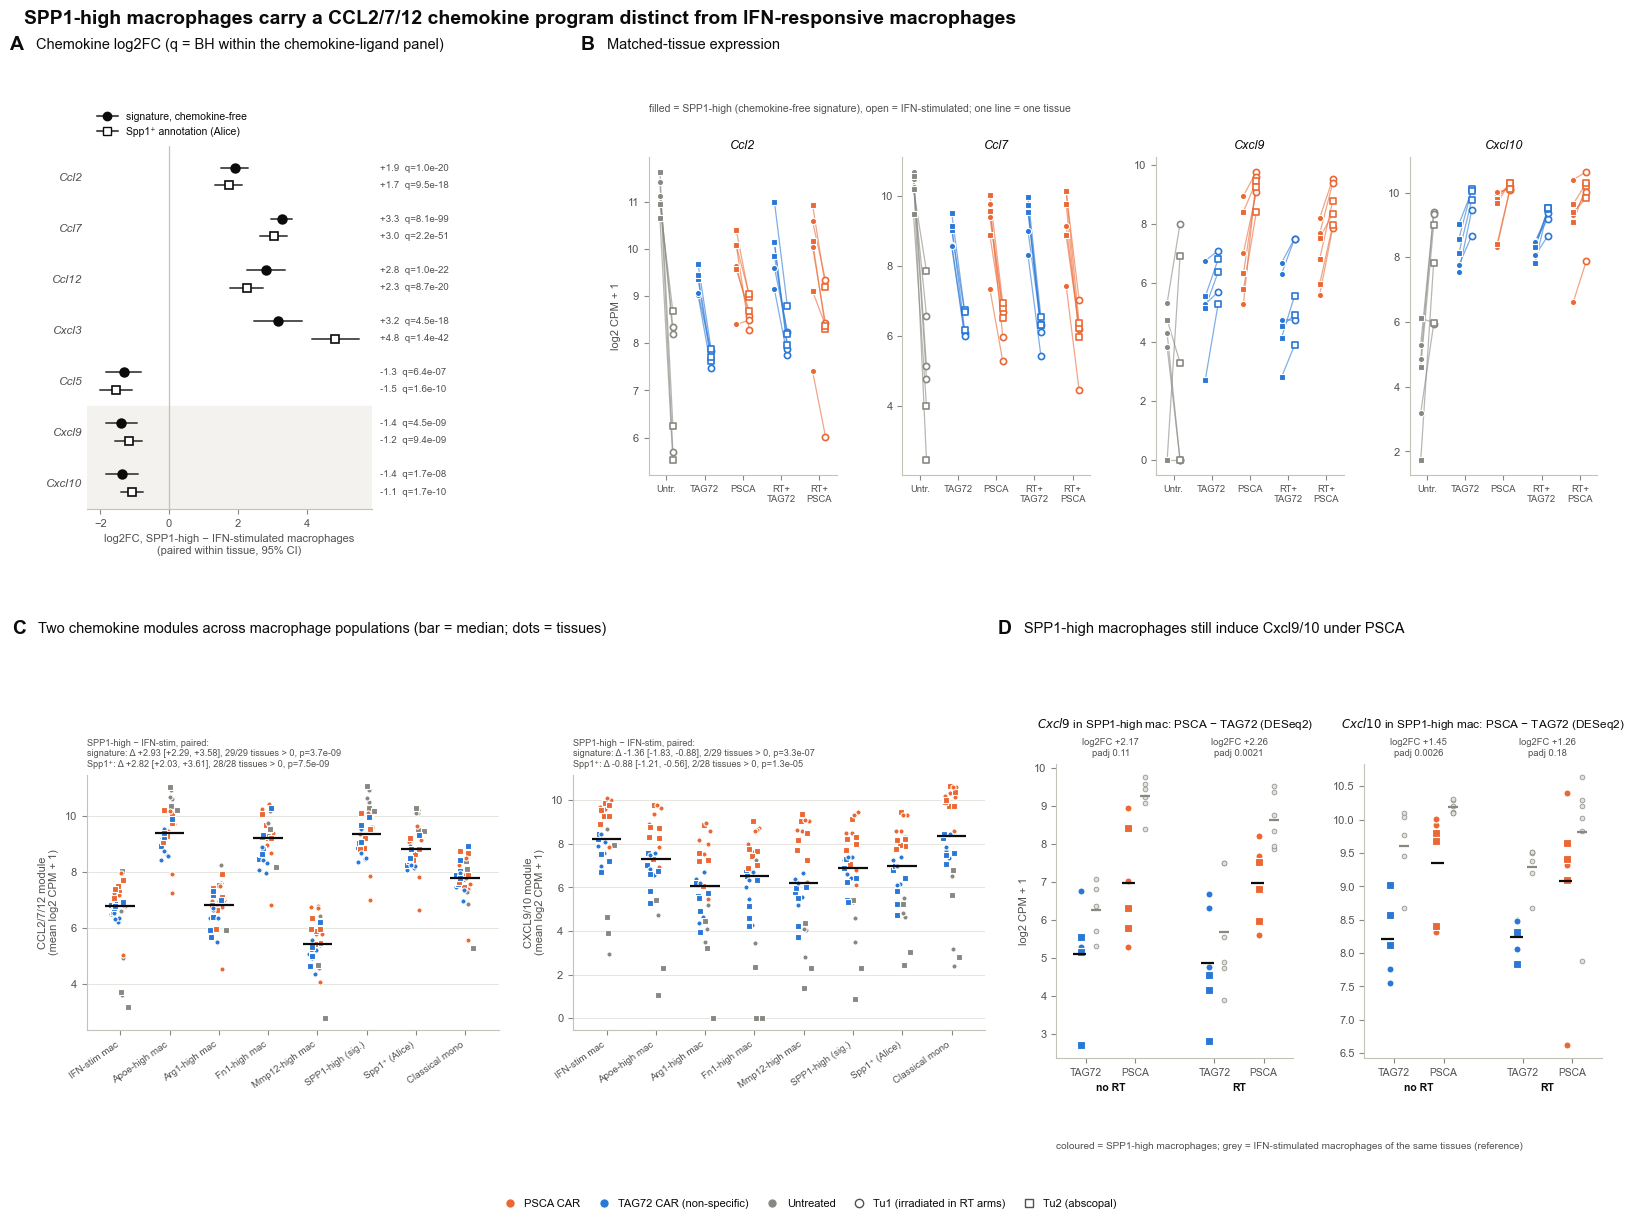

In [9]:
import scanpy as sc
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats
from pydeseq2.default_inference import DefaultInference
INF = DefaultInference(n_cpus=8)
CHEM_IN_SIG = ["Ccl2", "Ccl7", "Ccl8", "Ccl12"]
F5_CACHE = OUT/"fig5_pseudobulk.parquet"

if F5_CACHE.exists():
    PB5 = pd.read_parquet(F5_CACHE); PBM5 = pd.read_csv(OUT/"fig5_pseudobulk_meta.csv").set_index("key").loc[PB5.index]
    JAC = json.load(open(OUT/"fig5_definition_overlap.json"))
else:
    with h5py.File(SC_REF, "r") as f:
        obs = ad.io.read_elem(f["obs"]); var = ad.io.read_elem(f["var"])
        X = ad.io.read_elem(f["X"]); C = sp.csr_matrix(ad.io.read_elem(f["layers/counts"]))
    genes = pd.Index(var.index.astype(str))
    adata = ad.AnnData(X=X, obs=pd.DataFrame(index=obs.index), var=pd.DataFrame(index=genes)); del X
    sig = [g for g in pd.read_csv(SIG_CSV)["gene"] if g in genes]
    sig_nc = [g for g in sig if g not in CHEM_IN_SIG]
    sc.tl.score_genes(adata, sig_nc, score_name="sig_nc", ctrl_size=50, random_state=0)
    s_nc = adata.obs["sig_nc"].values; del adata
    o = cp.loc[obs.index]
    mac = o.is_mac.values
    spp1_nc = mac & (s_nc >= np.quantile(s_nc[mac], 0.75))
    ifn = (o.ct3 == "IFN_stimulated_Mac").values
    orig = o.SPP1_TAM.values
    JAC = dict(n_sig=len(sig), n_sig_nc=len(sig_nc), removed=[g for g in sig if g in CHEM_IN_SIG],
               jaccard_with_original=float((spp1_nc & orig).sum() / (spp1_nc | orig).sum()),
               n_spp1_nc=int(spp1_nc.sum()), n_orig=int(orig.sum()), overlap_ifn=int((spp1_nc & ifn).sum()))
    json.dump(JAC, open(OUT/"fig5_definition_overlap.json", "w"))
    G5 = {"SPP1nc_notIFN": spp1_nc & ~ifn, "IFNmac_notSPP1nc": ifn & ~spp1_nc}
    samples = design.index.tolist(); smp = o["sample"].values
    rows, cols, keys = [], [], []
    for gname, m in G5.items():
        for s in samples:
            sel = np.where(m & (smp == s))[0]
            if len(sel): r = len(keys); keys.append((gname, s, len(sel))); rows.append(np.full(len(sel), r)); cols.append(sel)
    Mi = sp.csr_matrix((np.ones(sum(map(len, rows))), (np.concatenate(rows), np.concatenate(cols))), shape=(len(keys), C.shape[0]))
    PB5 = pd.DataFrame((Mi @ C).toarray().astype(np.int64), columns=genes)
    PBM5 = pd.DataFrame(keys, columns=["group", "sample", "n_cells"]).merge(design.reset_index()[["sample", "arm", "site", "mouse", "cart", "RT"]], on="sample")
    PBM5["key"] = PBM5.group + "|" + PBM5["sample"]; PB5.index = PBM5.key; PBM5 = PBM5.set_index("key")
    PB5.to_parquet(F5_CACHE); PBM5.to_csv(OUT/"fig5_pseudobulk_meta.csv")
    del C
print(f"chemokine-free signature: {JAC['n_sig_nc']} genes (removed {JAC['removed']}); SPP1-high cells {JAC['n_spp1_nc']:,} "
      f"(original {JAC['n_orig']:,}); Jaccard with the original call {JAC['jaccard_with_original']:.2f}")

# one table of pseudobulks for everything figure 5 uses
PBX = pd.concat([PB, PB5[PB.columns]]); PBMX = pd.concat([PBM, PBM5[PBM.columns.intersection(PBM5.columns)]])
LX = np.log2(PBX.div(PBX.sum(1), axis=0) * 1e6 + 1)


def lvlx(group, gene, min_cells=MIN_CELLS):
    d = PBMX[(PBMX.group == group) & (PBMX.n_cells >= min_cells)]
    return pd.Series(LX.loc[d.index, gene].values, index=d["sample"].values)


DEFS = {"signature (chemokine-free)": ("SPP1nc_notIFN", "IFNmac_notSPP1nc"),
        "Spp1⁺ annotation (Alice)": ("SPP1alice_notIFN", "IFNmac_SPP1neg_alice")}
CH5 = ["Ccl2", "Ccl7", "Ccl12", "Cxcl3", "Ccl5", "Cxcl9", "Cxcl10"]
LIG = sorted({g for v in CAT["axes"].values() for g in v["ligands"]})


def paired_de(ga, gb):
    A = PBMX[(PBMX.group == ga) & (PBMX.n_cells >= MIN_CELLS)].set_index("sample")
    B = PBMX[(PBMX.group == gb) & (PBMX.n_cells >= MIN_CELLS)].set_index("sample")
    smp = [s for s in A.index if s in B.index]
    X = pd.concat([PBX.loc[[f"{ga}|{s}" for s in smp]].set_axis([f"{s}|A" for s in smp]),
                   PBX.loc[[f"{gb}|{s}" for s in smp]].set_axis([f"{s}|B" for s in smp])])
    meta = pd.DataFrame({"sample": smp * 2, "state": pd.Categorical(["A"] * len(smp) + ["B"] * len(smp), ["B", "A"])}, index=X.index)
    keep = (((X > 0).sum(0) >= 6) & (X.sum(0) >= 10 * len(X))) | X.columns.isin(LIG)
    X = X.loc[:, keep & ((X > 0).sum(0) >= 2)]
    dds = DeseqDataSet(counts=X, metadata=meta, design="~ sample + state", inference=INF, quiet=True); dds.deseq2()
    st = DeseqStats(dds, contrast=["state", "A", "B"], inference=INF, quiet=True); st.summary()
    r = st.results_df
    lg = r.index.isin(LIG) & r.pvalue.notna(); r["q_ligand_panel"] = np.nan
    r.loc[lg, "q_ligand_panel"] = multipletests(r.loc[lg, "pvalue"], method="fdr_bh")[1]
    return r.assign(n_samples=len(smp))


PDE = {lab: paired_de(*grp) for lab, grp in DEFS.items()}
pd.concat({k: v.loc[v.index.isin(LIG)] for k, v in PDE.items()}, names=["definition", "gene"]).to_csv(OUT/"fig5_paired_de_ligands.csv")
for lab, r in PDE.items():
    print(f"{lab}: " + ", ".join(f"{g} {r.loc[g, 'log2FoldChange']:+.2f} (q={r.loc[g, 'q_ligand_panel']:.3g})"
                                 for g in CH5 if g in r.index))


def psca_de(group):
    out = {}
    for c_, arms in [("no RT", ["CyPSCA", "CyT72"]), ("RT", ["RTCyPSCA", "RTCyT72"])]:
        d = PBMX[(PBMX.group == group) & (PBMX.n_cells >= MIN_CELLS) & PBMX.arm.isin(arms)]
        X = PBX.loc[d.index]
        meta = pd.DataFrame({"site": pd.Categorical(np.where(d.site == 1, "Tu1", "Tu2"), ["Tu2", "Tu1"]),
                             "car": pd.Categorical(np.where(d.arm.str.contains("PSCA"), "PSCA", "TAG72"), ["TAG72", "PSCA"])}, index=d.index)
        keep = (((X > 0).sum(0) >= 3) & (X.sum(0) >= 10 * len(X))) | X.columns.isin(["Cxcl9", "Cxcl10"])
        dds = DeseqDataSet(counts=X.loc[:, keep], metadata=meta, design="~ site + car", inference=INF, quiet=True); dds.deseq2()
        st = DeseqStats(dds, contrast=["car", "PSCA", "TAG72"], inference=INF, quiet=True); st.summary()
        out[c_] = st.results_df
    return out


PSCA5 = psca_de("SPP1nc_notIFN")
for c_, r in PSCA5.items():
    print(f"SPP1-high (chemokine-free) PSCA − TAG72, {c_}: " + ", ".join(
        f"{g} {r.loc[g, 'log2FoldChange']:+.2f} (padj={r.loc[g, 'padj']:.3g})" for g in ["Cxcl9", "Cxcl10"]))


def f5A(sf):
    ax = sf.add_axes([0.14, 0.16, 0.50, 0.64])
    for i, g in enumerate(CH5):
        for j, (lab, mk, fill) in enumerate([(list(DEFS)[0], "o", INK), (list(DEFS)[1], "s", "white")]):
            r = PDE[lab]
            if g not in r.index: continue
            y = i + (j - 0.5) * 0.34; lfc, se = r.loc[g, "log2FoldChange"], r.loc[g, "lfcSE"]
            ax.plot([lfc - 1.96 * se, lfc + 1.96 * se], [y, y], color=INK2, lw=1.4)
            ax.plot(lfc, y, marker=mk, ms=6.3, mfc=fill, mec=INK, mew=1.2, ls="")
            q = r.loc[g, "q_ligand_panel"]
            ax.text(1.03, y, f"{lfc:+.1f}  q={q:.1e}" if q < 0.001 else f"{lfc:+.1f}  q={q:.3f}",
                    transform=mpl.transforms.blended_transform_factory(ax.transAxes, ax.transData), fontsize=7, va="center", color=INK2)
    ax.axvline(0, color=AXIS, lw=0.9); ax.set_yticks(range(len(CH5))); ax.set_yticklabels(CH5, style="italic", fontsize=8.5)
    ax.set_ylim(len(CH5) - 0.5, -0.6); ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
    ax.axhspan(4.5, 6.5, color="#f3f2ee", zorder=0)
    ax.set_xlabel("log2FC, SPP1-high − IFN-stimulated macrophages\n(paired within tissue, 95% CI)", fontsize=8)
    ax.legend(handles=[Line2D([], [], marker="o", ls="-", color=INK2, mfc=INK, mec=INK, label="signature, chemokine-free"),
                       Line2D([], [], marker="s", ls="-", color=INK2, mfc="white", mec=INK, label="Spp1⁺ annotation (Alice)")],
              loc="lower left", bbox_to_anchor=(0, 1.0), ncol=1, frameon=False, fontsize=7.5)
    panel_label(sf, "A", "Chemokine log2FC (q = BH within the chemokine-ligand panel)")


def f5B(sf):
    gs = sf.add_gridspec(1, 4, left=0.07, right=0.99, top=0.78, bottom=0.22, wspace=0.35)
    X = {"NoTx": 0, "CyT72": 1.3, "CyPSCA": 2.6, "RTCyT72": 3.9, "RTCyPSCA": 5.2}
    ga, gb = DEFS["signature (chemokine-free)"]
    for k, g in enumerate(["Ccl2", "Ccl7", "Cxcl9", "Cxcl10"]):
        ax = sf.add_subplot(gs[k]); a = lvlx(ga, g); b = lvlx(gb, g)
        for s in a.index.intersection(b.index):
            arm, site = design.loc[s, "arm"], design.loc[s, "site"]; x0 = X[arm]
            ax.plot([x0 - 0.22, x0 + 0.22], [a[s], b[s]], color=CAR_COL[CAR_OF[arm]], lw=0.9, alpha=0.6, zorder=2)
            dots(ax, x0 - 0.22, a[s], arm, site, s=20); dots(ax, x0 + 0.22, b[s], arm, site, s=20, hollow=True)
        ax.set_xticks(list(X.values())); ax.set_xticklabels(["Untr.", "TAG72", "PSCA", "RT+\nTAG72", "RT+\nPSCA"], fontsize=6.8)
        ax.set_title(g, fontsize=9, style="italic"); ax.set_xlim(-0.6, 5.8)
        if k == 0: ax.set_ylabel("log2 CPM + 1", fontsize=8)
    sf.text(0.07, 0.86, "filled = SPP1-high (chemokine-free signature), open = IFN-stimulated; one line = one tissue",
            fontsize=7.5, color=INK2)
    panel_label(sf, "B", "Matched-tissue expression")


POPS5 = [("IFN_stimulated_Mac", "IFN-stim mac"), ("Apoe_high_Mac", "Apoe-high mac"), ("Arg1_high_Mac", "Arg1-high mac"),
         ("Fn1_high_Mac", "Fn1-high mac"), ("Mmp12_high_Mac", "Mmp12-high mac"), ("SPP1nc_notIFN", "SPP1-high (sig.)"),
         ("SPP1alice_notIFN", "Spp1⁺ (Alice)"), ("Classical_Mono", "Classical mono")]
MODS = {"CCL2/7/12 module": ["Ccl2", "Ccl7", "Ccl12"], "CXCL9/10 module": ["Cxcl9", "Cxcl10"]}
MOD_ROWS = []


def f5C(sf):
    gs = sf.add_gridspec(1, 2, left=0.08, right=0.99, top=0.72, bottom=0.27, wspace=0.18)
    for k, (mname, gl) in enumerate(MODS.items()):
        ax = sf.add_subplot(gs[k])
        for i, (grp, lab) in enumerate(POPS5):
            v = pd.concat([lvlx(grp, g) for g in gl], axis=1).mean(1)
            for s, val in v.items():
                dots(ax, i + np.random.default_rng(sum(map(ord, s))).uniform(-0.18, 0.18), val, design.loc[s, "arm"], design.loc[s, "site"], s=14)
            mean_tick(ax, i, v.median(), w=0.3)
        ax.set_xticks(range(len(POPS5))); ax.set_xticklabels([l for _, l in POPS5], fontsize=7, rotation=35, ha="right")
        ax.set_ylabel(f"{mname}\n(mean log2 CPM + 1)", fontsize=8); ax.yaxis.grid(True); ax.set_axisbelow(True)
        txt = []
        for dname, (ga, gb) in DEFS.items():
            a = pd.concat([lvlx(ga, g) for g in gl], axis=1).mean(1); b = pd.concat([lvlx(gb, g) for g in gl], axis=1).mean(1)
            s_ = a.index.intersection(b.index); dlt = a[s_] - b[s_]
            h = stats.t.ppf(0.975, len(dlt) - 1) * dlt.std() / np.sqrt(len(dlt)); p_ = stats.wilcoxon(dlt).pvalue
            MOD_ROWS.append(dict(module=mname, definition=dname, n=len(dlt), mean_diff=dlt.mean(), lo=dlt.mean() - h,
                                  hi=dlt.mean() + h, p_wilcoxon=p_, frac_positive=float((dlt > 0).mean())))
            txt.append(f"{dname.split(' ')[0]}: Δ {dlt.mean():+.2f} [{dlt.mean()-h:+.2f}, {dlt.mean()+h:+.2f}], "
                       f"{int((dlt > 0).sum())}/{len(dlt)} tissues > 0, p={p_:.1e}")
        ax.set_title("SPP1-high − IFN-stim, paired:\n" + "\n".join(txt), fontsize=6.6, color=INK2, loc="left")
    panel_label(sf, "C", "Two chemokine modules across macrophage populations (bar = median; dots = tissues)")


def f5D(sf):
    gs = sf.add_gridspec(1, 2, left=0.10, right=0.99, top=0.74, bottom=0.22, wspace=0.3)
    ga, gb = DEFS["signature (chemokine-free)"]
    for k, g in enumerate(["Cxcl9", "Cxcl10"]):
        ax = sf.add_subplot(gs[k]); a = lvlx(ga, g); b = lvlx(gb, g)
        X = {"CyT72": 0, "CyPSCA": 1, "RTCyT72": 2.6, "RTCyPSCA": 3.6}
        for arm, x0 in X.items():
            sa = [s for s in a.index if design.loc[s, "arm"] == arm]
            for s in sa: dots(ax, x0 - 0.13 + np.random.default_rng(len(s)).uniform(-0.05, 0.05), a[s], arm, design.loc[s, "site"], s=26)
            mean_tick(ax, x0 - 0.13, a[sa].mean(), w=0.13)
            sb = [s for s in b.index if design.loc[s, "arm"] == arm]
            ax.scatter(np.full(len(sb), x0 + 0.2), b[sb], s=12, color=GRID, edgecolor=MUTED, lw=0.5, zorder=2)
            mean_tick(ax, x0 + 0.2, b[sb].mean(), w=0.1, color=MUTED)
        tr = mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes)
        for c_, xm in [("no RT", 0.5), ("RT", 3.1)]:
            r = PSCA5[c_].loc[g]
            ax.text(xm, 1.02, f"log2FC {r.log2FoldChange:+.2f}\npadj {r.padj:.2g}", transform=tr,
                    ha="center", va="bottom", fontsize=6.8, color=INK2)
            under_label(ax, xm, c_, 1, bold=True)
        ax.set_xticks(list(X.values())); ax.set_xticklabels(["TAG72", "PSCA", "TAG72", "PSCA"], fontsize=7.5)
        ax.set_title(f"$\\it{{{g}}}$ in SPP1-high mac: PSCA − TAG72 (DESeq2)", fontsize=8.5, pad=26); ax.set_xlim(-0.6, 4.2)
        if k == 0: ax.set_ylabel("log2 CPM + 1", fontsize=8)
    sf.text(0.10, 0.06, "coloured = SPP1-high macrophages; grey = IFN-stimulated macrophages of the same tissues (reference)",
            fontsize=7.2, color=INK2)
    panel_label(sf, "D", "SPP1-high macrophages still induce Cxcl9/10 under PSCA")


fig5 = plt.figure(figsize=(16, 11.5))
top5, bot5 = fig5.subfigures(2, 1, height_ratios=[1.0, 1.0], hspace=0.03)
a5, b5 = top5.subfigures(1, 2, width_ratios=[0.8, 1.45]); f5A(a5); f5B(b5)
c5, d5 = bot5.subfigures(1, 2, width_ratios=[1.45, 0.9]); f5C(c5); f5D(d5)
legend_car_site(fig5)
fig5.suptitle("SPP1-high macrophages carry a CCL2/7/12 chemokine program distinct from IFN-responsive macrophages",
              x=0.01, y=1.02, ha="left", fontsize=14, fontweight="bold")
save(fig5, "Figure5_SPP1_chemokines"); plt.show()
MOD_STATS = pd.DataFrame(MOD_ROWS).drop_duplicates(["module", "definition"]); MOD_STATS.to_csv(OUT/"fig5_module_paired_tests.csv", index=False)
for fn, sz, nm in [(f5A, (7.5, 4.8), "Fig5A"), (f5B, (13, 3.8), "Fig5B"), (f5C, (11, 4.2), "Fig5C"), (f5D, (7.5, 4.2), "Fig5D")]:
    save_panel(fn, sz, nm)

## Captions and summary

In [10]:
e_nk = RES1B[("NK", "cyto_effector_noCcl5")]; e_core = RES1B[("NK", "cyto_core")]
e_cd8 = RES1B[("CD8_T", "cyto_core")]
CAPTIONS = f"""# Figure captions

**Figure 1 — {FIG1_TITLE}.**
(A) Per-cell expression of a core cytotoxic module (Gzmb, Prf1, Nkg7, Ctsw; colour) and the fraction of
cells co-expressing Gzmb and Prf1 in the same cell (size), by cell type, treatment and tumour site; open
marks = fewer than two samples with ≥ 5 cells; numbers = cells. (A′) The core module tracks the broader
Ccl5-free effector score in every sample. (B) PSCA − TAG72 effects (within-arm SD units, 95% CI) by RT
stratum. NK, core module: no RT {e_core['no RT']['est']:+.2f} (p={e_core['no RT']['p']:.2f}), RT
{e_core['RT']['est']:+.2f} (p={e_core['RT']['p']:.3f}), pooled {e_core['pooled']['est']:+.2f}
(p={e_core['pooled']['p']:.3f}); Ccl5-free effector score pooled {e_nk['pooled']['est']:+.2f}
(p={e_nk['pooled']['p']:.3f}), CAR × RT p={e_nk['CARxRT']['p']:.2f}. CD8, core module pooled
{e_cd8['pooled']['est']:+.2f} (p={e_cd8['pooled']['p']:.2f}). Right: every sample (shaded = RT). (C) Per-sample
fractions of NK and CD8 cells expressing Gzmb, Prf1, both (computed per cell) and Ifng. (D) NK and CD8
abundance as % of all cells; labels give type cells / all cells per condition. p: exact relabelling over
samples; CI: pooled-variance t interval. *PSCA CAR-T therapy is associated with higher NK-cell cytotoxic
effector transcription, most prominently in combination with RT; the core Gzmb/Prf1/Nkg7/Ctsw module points
the same way but is not significant on its own. CD8 cytotoxic responses remain uncertain because of sparse
sampling.* These are transcriptional readouts, not measurements of killing.

**Figure 2 — Antigen-specific CAR-T treatment induces a reproducible myeloid interferon-response program.**
(A) PSCA − TAG72 effects on four interferon programs in each myeloid population, per tumour site (Tu1 =
irradiated in RT mice, Tu2 = abscopal) within each RT stratum (SD units). Stars between a Tu1 | Tu2 pair are the
site-averaged stratum test (exact p); within one site the smallest attainable exact p is 0.10 (3 v 3 tumours), so
the per-site cells carry estimates only. Tumour cells are shown separately. The Reactome "IFN-γ signaling" set is 19
receptor and kinase components (Ifngr1/2, Jak2, Camk2, Mapk, Ptpn, Socs) rather than induced genes, so it is
not expected to move; the response is in the induced (Hallmark / ISG) genes. (B) Gene-level DESeq2 log2FC (PSCA − TAG72)
for Gbp2, Irf1, Stat1, Cxcl9, Cxcl10 and Cd274, per tumour site (DESeq2 within one site and one RT stratum, 3 v 2-3
tumours; * padj, BH over that fit); ▼ padj < 0.05 in both RT strata in the site-pooled fits.
(C) ISG-core and Hallmark IFN-γ scores per sample in classical monocytes and SPP1-TAMs; lines join the two
tumours of one mouse (untreated tumours sit ≈ 10-20 SD lower and are omitted for scale). A transcriptional response consistent with interferon signalling — not a measurement
of IFN-γ protein or its source.

**Figure 3 — PSCA CAR-T therapy induces MHC-I and MHC-II antigen-processing programs in tumour-associated
myeloid cells.** (A) Pooled PSCA − TAG72 effects (95% CI) on MHC-I machinery and MHC-II core programs;
✓ = p < 0.05 in both RT strata. (B) Gene-level log2FC for MHC-I and MHC-II machinery without and with RT.
(C) MHC-II core score per sample. Tumour-cell MHC-II is excluded: it is predominantly ambient macrophage RNA
(Figure S3). The data show increased antigen-presentation machinery, not presentation to or priming of T cells.

**Figure S3 — Tumour-cell MHC-II largely reflects macrophage RNA.** (A) Intrinsic fraction of each MHC gene's
signal in tumour pseudobulks (per sample; MHC-I mostly the tumour's own, MHC-II mostly ambient). (B) The CAR × RT
interaction on tumour MHC genes in all tumour cells vs tumour cells with no macrophage-marker reads: it weakens
and loses significance in clean cells, so it should not be read as tumour-intrinsic MHC-II induction.

**Figure 4 — Antigen-specific CAR-T effects are more consistently detected than radiotherapy effects.**
(A) Pooled effects (95% CI) of PSCA vs TAG72, direct RT (Tu1) and indirect RT (Tu2) on the same programs and
populations; marker fill = evidence tier from the claims ledger, triangles = a single mouse flips a stratum.
(B) Replication matrix (pooled effect; ★ BH q < 0.05; ● p < 0.05 in both strata/backgrounds; ◆ leave-one-out
stable). (C) Lower ISG and Cxcl9 in the abscopal tumour with RT, in both CAR backgrounds. With three tumours a
side, the smallest attainable exact p within one background is 0.10, so the evidence is the agreement of both
backgrounds (pooled q < 0.05 for ISG in IFN-stimulated macrophages, panel B) plus gene-level DESeq2 (Cxcl9
q = 0.004 / 0.024 in the TAG72 background). At this sampling point comparatively few RT effects meet these
criteria; this does not show that RT was biologically inactive or that smaller effects are absent.

**Figure 5 — SPP1-high macrophages carry a CCL2/7/12 chemokine program distinct from IFN-responsive
macrophages.** SPP1-high cells are defined twice without reusing any compared chemokine: the SPP1-TAM
signature with Ccl2/7/8/12 removed ({JAC['n_sig_nc']} genes; Jaccard {JAC['jaccard_with_original']:.2f} with the original call), and
Alice's Spp1⁺ annotation. (A) Paired DESeq2 log2FC vs IFN-stimulated macrophages (95% CI; BH within the
chemokine-ligand panel). (B) Matched-tissue expression. (C) CCL2/7/12 and CXCL9/10 module scores across
macrophage populations, with paired tests. (D) SPP1-high macrophages still raise Cxcl9/10 under PSCA: all four
PSCA − TAG72 estimates are positive (log2FC +1.3 to +2.3); two reach padj < 0.01 (Cxcl9 with RT, Cxcl10
without RT).
*SPP1-TAMs retain a distinct chemokine program enriched for CCL2, CCL7 and CCL12 relative to IFN-stimulated
macrophages, despite mounting a substantial PSCA-associated interferon response.*
"""
(OUT/"captions.md").write_text(CAPTIONS)
print("=" * 100); print("SUMMARY — report these back"); print("=" * 100)
print(f"\n[figures] {OUT}:"); [print(f"    {p_.name}") for p_ in sorted(OUT.glob("Figure*"))]
print(f"[panels]  {len(list(PANELS.glob('*.png')))} single-panel PNGs in {PANELS}")
print(f"\n[Fig 1] NK core module PSCA: no RT {e_core['no RT']['est']:+.2f} (p={e_core['no RT']['p']:.3f}), RT "
      f"{e_core['RT']['est']:+.2f} (p={e_core['RT']['p']:.3f}), pooled {e_core['pooled']['est']:+.2f} "
      f"[{e_core['pooled']['lo']:+.2f}, {e_core['pooled']['hi']:+.2f}] (p={e_core['pooled']['p']:.3f})")
print(f"        CD8 core module pooled {e_cd8['pooled']['est']:+.2f} [{e_cd8['pooled']['lo']:+.2f}, {e_cd8['pooled']['hi']:+.2f}] "
      f"(p={e_cd8['pooled']['p']:.3f})")
print(f"[Fig 4] replicated cells per effect: {RM.groupby('effect').replicated.sum().to_dict()} of "
      f"{RM.groupby('effect').size().to_dict()}; q<0.05: {RM[RM.q < 0.05].groupby('effect').size().to_dict()}")
print(f"[Fig 5] definitions: {JAC}")
print(MOD_STATS.round(3).to_string(index=False))
print("=" * 100)

SUMMARY — report these back

[figures] /Users/janzules/Roselab/Spatial/CAR_T/results/mhc_cytotox_figures:
    Figure1_cytotoxic.pdf
    Figure1_cytotoxic.png
    Figure2_interferon.pdf
    Figure2_interferon.png
    Figure3_antigen_presentation.pdf
    Figure3_antigen_presentation.png
    Figure4_PSCA_vs_RT.pdf
    Figure4_PSCA_vs_RT.png
    Figure5_SPP1_chemokines.pdf
    Figure5_SPP1_chemokines.png
    FigureS3_tumour_MHC_QC.pdf
    FigureS3_tumour_MHC_QC.png
[panels]  18 single-panel PNGs in /Users/janzules/Roselab/Spatial/CAR_T/results/mhc_cytotox_figures/panels

[Fig 1] NK core module PSCA: no RT +0.17 (p=0.800), RT +1.38 (p=0.065), pooled +0.78 [-0.43, +1.98] (p=0.150)
        CD8 core module pooled +0.00 [-1.23, +1.23] (p=0.998)
[Fig 4] replicated cells per effect: {'PSCA': 15, 'direct RT': 0, 'indirect RT': 0} of {'PSCA': 22, 'direct RT': 22, 'indirect RT': 22}; q<0.05: {'PSCA': 18, 'indirect RT': 1}
[Fig 5] definitions: {'n_sig': 50, 'n_sig_nc': 46, 'removed': ['Ccl7', 'Ccl8',